# Final 3D Metric Statistics Across Five Seeds


In [1]:
from pathlib import Path
import numpy as np

# Get offline results directory
project = Path.cwd()
if not (project / "offline_results").is_dir():
    project = project.parent
results_dir = project / "offline_results"
assert results_dir.is_dir(), f"Not found: {results_dir}"

SEEDS = [0, 1, 2, 3, 4]
ORGANS = {1: "Esophagus", 2: "Heart", 3: "Trachea", 4: "Aorta"}
HD_PERCENTILE = 95
results = {}
NSD_TOLERANCE = 3


def load_offline_metrics(folder):
    # Load saved 3D Dice, penalized HD, and NSD
    dice = np.load(folder / "dice_3d_val.npy").astype(float)
    hd = np.load(folder / "hd_3d_val.npy").astype(float)
    nsd = np.load(folder / "nsd_3d_val.npy").astype(float)
    global NSD_TOLERANCE
    tolerance = float(np.load(folder / "nsd_tolerance_mm.npy"))
    if NSD_TOLERANCE is None:
        NSD_TOLERANCE = tolerance
    assert np.isclose(tolerance, NSD_TOLERANCE), "Different NSD tolerances"
    patients = np.load(folder / "patients_val.npy")
    assert dice.ndim == 2 and dice.shape[1] == 5, f"Unexpected shape: {folder}"
    assert hd.shape == nsd.shape == dice.shape and patients.shape == (len(dice),)
    assert len(set(patients.tolist())) == len(patients), "Duplicate patient IDs"

    return dice, hd, nsd, patients


def statistics(values):
    values = np.asarray(values, dtype=float)
    valid = values[np.isfinite(values)]  # exclude undefined values, but keep real zeros (including Dice failures)
    if len(valid) == 0:
        return np.nan, np.nan, 0
    mean = np.mean(valid)
    std = np.std(valid, ddof=0)
    count = len(valid)
    return mean, std, count


def analyse_setting(setting):
    # Rows are seeds, columns are organs, without background
    dice_per_seed = np.full((5, 4), np.nan)
    hd_per_seed = np.full((5, 4), np.nan)
    nsd_per_seed = np.full((5, 4), np.nan)
    patient_sets = []
    for seed in SEEDS:
        folder = results_dir / setting / f"ce_seed{seed}" / "metrics_3d"
        filenames = ["dice_3d_val.npy", "hd_3d_val.npy", "nsd_3d_val.npy", "nsd_tolerance_mm.npy", "patients_val.npy"]
        missing = []
        for name in filenames:
            if not (folder / name).is_file():
                missing.append(name)
        if missing:
            print(f"{setting}, seed {seed}: missing {missing} is excluded.")
            continue

        dice, hd, nsd, patients = load_offline_metrics(folder)

        # Checks
        assert dice.ndim == 2 and dice.shape[1] == 5, f"Unexpected shape in {folder}"
        assert hd.shape == nsd.shape == dice.shape and patients.shape == (len(dice),)
        assert len(set(patients.tolist())) == len(patients), "Duplicate patient IDs"

        patient_set = set(patients.tolist())
        if patient_sets and patient_set != patient_sets[0]:
            print(f"WARNING: {setting}, seed {seed}: different patients from other seeds.")
        patient_sets.append(patient_set)

        for class_id, organ in ORGANS.items():
            # Each seed contributes one patient-average score per organ
            dice_per_seed[seed, class_id - 1] = statistics(dice[:, class_id])[0]
            hd_per_seed[seed, class_id - 1] = statistics(hd[:, class_id])[0]
            nsd_per_seed[seed, class_id - 1] = statistics(nsd[:, class_id])[0]

    # Each available organ has equal weight in the overall score for a seed
    overall_dice = np.full(5, np.nan)
    overall_hd = np.full(5, np.nan)
    overall_nsd = np.full(5, np.nan)
    for seed in SEEDS:
        overall_dice[seed] = statistics(dice_per_seed[seed])[0]
        overall_hd[seed] = statistics(hd_per_seed[seed])[0]
        overall_nsd[seed] = statistics(nsd_per_seed[seed])[0]
        dice_count = np.isfinite(dice_per_seed[seed]).sum()
        hd_count = np.isfinite(hd_per_seed[seed]).sum()
        if dice_count < 4 or hd_count < 4:
            print(f"{setting}, seed {seed}: overall uses {dice_count}/4 DSC organs "
                  f"and {hd_count}/4 HD organs.")

    results[setting] = {
        "dice": dice_per_seed,
        "hd": hd_per_seed,
        "nsd": nsd_per_seed,
        "overall_dice": overall_dice,
        "overall_hd": overall_hd,
        "overall_nsd": overall_nsd,
        "patient_sets": patient_sets}

    print("\nPer-organ statistics across seed means:")
    print(f"{'Organ':<14} {'DSC mean':>10} {'DSC std':>10} {'seeds':>6} "
          f"{f'HD{HD_PERCENTILE} mean mm':>14} {f'HD{HD_PERCENTILE} std mm':>13} {'seeds':>6} {'NSD mean':>10} {'NSD std':>10} {'seeds':>6}")
    
    for class_id, organ in ORGANS.items():
        dice_mean, dice_std, dice_num = statistics(dice_per_seed[:, class_id - 1])
        hd_mean, hd_std, hd_num = statistics(hd_per_seed[:, class_id - 1])
        nsd_mean, nsd_std, nsd_num = statistics(nsd_per_seed[:, class_id - 1])
        print(f"{organ:<14} {dice_mean:10.4f} {dice_std:10.4f} {dice_num:6d} "
              f"{hd_mean:14.4f} {hd_std:13.4f} {hd_num:6d} {nsd_mean:10.4f} {nsd_std:10.4f} {nsd_num:6d}")


def print_overall(setting):
    setting_results = results[setting]
    print("Overall scores per seed (mean of available organ means):")
    for seed in SEEDS:
        print(f"Seed {seed}: DSC={setting_results['overall_dice'][seed]:.4f}, "
              f"HD{HD_PERCENTILE}={setting_results['overall_hd'][seed]:.4f} mm, NSD={setting_results['overall_nsd'][seed]:.4f}")
    for name, key in [("DSC", "overall_dice"), (f"HD{HD_PERCENTILE} (mm)", "overall_hd"), (f"NSD ({NSD_TOLERANCE:g} mm)", "overall_nsd")]:
        mean, std, count = statistics(setting_results[key])
        print(f"{name}: mean={mean:.4f}, std={std:.4f}, "
              f"valid seeds={count}, invalid/missing seeds={5 - count}")


# Baseline

In [2]:
analyse_setting("segthor_baseline")


Per-organ statistics across seed means:
Organ            DSC mean    DSC std  seeds   HD95 mean mm   HD95 std mm  seeds   NSD mean    NSD std  seeds
Esophagus          0.5193     0.0162      5        15.9206        3.4926      5     0.7012     0.0157      5
Heart              0.8688     0.0086      5        22.1200        7.4924      5     0.6404     0.0170      5
Trachea            0.8119     0.0089      5        32.1246        7.6058      5     0.8962     0.0086      5
Aorta              0.7815     0.0106      5        24.3359        9.2030      5     0.7591     0.0120      5


In [3]:
print_overall("segthor_baseline")

Overall scores per seed (mean of available organ means):
Seed 0: DSC=0.7549, HD95=20.6031 mm, NSD=0.7663
Seed 1: DSC=0.7359, HD95=26.7459 mm, NSD=0.7409
Seed 2: DSC=0.7464, HD95=21.6216 mm, NSD=0.7480
Seed 3: DSC=0.7412, HD95=25.3151 mm, NSD=0.7421
Seed 4: DSC=0.7486, HD95=23.8408 mm, NSD=0.7488
DSC: mean=0.7454, std=0.0065, valid seeds=5, invalid/missing seeds=0
HD95 (mm): mean=23.6253, std=2.2711, valid seeds=5, invalid/missing seeds=0
NSD (3 mm): mean=0.7492, std=0.0091, valid seeds=5, invalid/missing seeds=0


## Preprocessed

In [4]:
analyse_setting("segthor_preprocessed")


Per-organ statistics across seed means:
Organ            DSC mean    DSC std  seeds   HD95 mean mm   HD95 std mm  seeds   NSD mean    NSD std  seeds
Esophagus          0.5327     0.0224      5        20.4701        8.4838      5     0.7046     0.0249      5
Heart              0.8931     0.0096      5        18.0926        8.9710      5     0.6977     0.0256      5
Trachea            0.8190     0.0056      5        22.0091       13.0309      5     0.9003     0.0084      5
Aorta              0.8278     0.0131      5        19.4654        3.2419      5     0.8209     0.0191      5


In [5]:
print_overall("segthor_preprocessed")

Overall scores per seed (mean of available organ means):
Seed 0: DSC=0.7714, HD95=21.6953 mm, NSD=0.7921
Seed 1: DSC=0.7625, HD95=17.7495 mm, NSD=0.7785
Seed 2: DSC=0.7582, HD95=19.8324 mm, NSD=0.7679
Seed 3: DSC=0.7823, HD95=13.2933 mm, NSD=0.8024
Seed 4: DSC=0.7663, HD95=27.4761 mm, NSD=0.7636
DSC: mean=0.7681, std=0.0083, valid seeds=5, invalid/missing seeds=0
HD95 (mm): mean=20.0093, std=4.6656, valid seeds=5, invalid/missing seeds=0
NSD (3 mm): mean=0.7809, std=0.0146, valid seeds=5, invalid/missing seeds=0


## Noise

In [6]:
analyse_setting("segthor_noise")


Per-organ statistics across seed means:
Organ            DSC mean    DSC std  seeds   HD95 mean mm   HD95 std mm  seeds   NSD mean    NSD std  seeds
Esophagus          0.5286     0.0148      5        17.0544        6.4361      5     0.6968     0.0351      5
Heart              0.8918     0.0097      5        24.9411        7.0397      5     0.6932     0.0267      5
Trachea            0.8283     0.0098      5        14.8851        1.5845      5     0.8984     0.0072      5
Aorta              0.8250     0.0169      5        17.4224        3.3438      5     0.8199     0.0281      5


In [7]:
print_overall("segthor_noise")

Overall scores per seed (mean of available organ means):
Seed 0: DSC=0.7743, HD95=18.1121 mm, NSD=0.7934
Seed 1: DSC=0.7814, HD95=16.7609 mm, NSD=0.8040
Seed 2: DSC=0.7570, HD95=19.9524 mm, NSD=0.7657
Seed 3: DSC=0.7708, HD95=18.6932 mm, NSD=0.7741
Seed 4: DSC=0.7586, HD95=19.3600 mm, NSD=0.7480
DSC: mean=0.7684, std=0.0093, valid seeds=5, invalid/missing seeds=0
HD95 (mm): mean=18.5757, std=1.0984, valid seeds=5, invalid/missing seeds=0
NSD (3 mm): mean=0.7770, std=0.0199, valid seeds=5, invalid/missing seeds=0


## Elastic deformations

In [8]:
analyse_setting("segthor_Vnet_deformations")


Per-organ statistics across seed means:
Organ            DSC mean    DSC std  seeds   HD95 mean mm   HD95 std mm  seeds   NSD mean    NSD std  seeds
Esophagus          0.5486     0.0178      5        12.9447        2.0472      5     0.7261     0.0163      5
Heart              0.9080     0.0051      5        27.9047       12.0127      5     0.7280     0.0255      5
Trachea            0.8339     0.0068      5        18.9788       10.9413      5     0.9065     0.0091      5
Aorta              0.8464     0.0134      5        17.8122        7.3068      5     0.8541     0.0236      5


In [9]:
print_overall("segthor_Vnet_deformations")

Overall scores per seed (mean of available organ means):
Seed 0: DSC=0.7961, HD95=17.8951 mm, NSD=0.8177
Seed 1: DSC=0.7896, HD95=29.4431 mm, NSD=0.8088
Seed 2: DSC=0.7727, HD95=20.4799 mm, NSD=0.7801
Seed 3: DSC=0.7828, HD95=16.4105 mm, NSD=0.8048
Seed 4: DSC=0.7799, HD95=12.8219 mm, NSD=0.8070
DSC: mean=0.7842, std=0.0080, valid seeds=5, invalid/missing seeds=0
HD95 (mm): mean=19.4101, std=5.5947, valid seeds=5, invalid/missing seeds=0
NSD (3 mm): mean=0.8037, std=0.0126, valid seeds=5, invalid/missing seeds=0


## AdamW with weight decay 1e-4

In [10]:
analyse_setting("segthor_AdamW_weight_decay")


Per-organ statistics across seed means:
Organ            DSC mean    DSC std  seeds   HD95 mean mm   HD95 std mm  seeds   NSD mean    NSD std  seeds
Esophagus          0.5605     0.0210      5        14.9074        3.0523      5     0.7321     0.0229      5
Heart              0.9039     0.0115      5        23.0446        7.2082      5     0.7173     0.0347      5
Trachea            0.8296     0.0072      5        30.3207       28.5605      5     0.8977     0.0099      5
Aorta              0.8358     0.0092      5        22.0051        1.8686      5     0.8362     0.0110      5


In [11]:
print_overall("segthor_AdamW_weight_decay")

Overall scores per seed (mean of available organ means):
Seed 0: DSC=0.7912, HD95=22.5347 mm, NSD=0.8101
Seed 1: DSC=0.7937, HD95=34.1001 mm, NSD=0.8113
Seed 2: DSC=0.7777, HD95=19.6193 mm, NSD=0.7874
Seed 3: DSC=0.7798, HD95=21.0917 mm, NSD=0.7845
Seed 4: DSC=0.7698, HD95=15.5014 mm, NSD=0.7859
DSC: mean=0.7825, std=0.0089, valid seeds=5, invalid/missing seeds=0
HD95 (mm): mean=22.5695, std=6.2258, valid seeds=5, invalid/missing seeds=0
NSD (3 mm): mean=0.7958, std=0.0122, valid seeds=5, invalid/missing seeds=0


## SGD with Nesterov momentum

In [12]:
analyse_setting("segthor_SGD")


Per-organ statistics across seed means:
Organ            DSC mean    DSC std  seeds   HD95 mean mm   HD95 std mm  seeds   NSD mean    NSD std  seeds
Esophagus          0.4814     0.0261      5        29.0363       16.8946      5     0.6441     0.0225      5
Heart              0.8847     0.0027      5        21.0975        7.8309      5     0.6468     0.0100      5
Trachea            0.8047     0.0146      5        31.4536       11.7281      5     0.8810     0.0147      5
Aorta              0.7856     0.0106      5        21.4482        5.1506      5     0.7582     0.0212      5


In [13]:
print_overall("segthor_SGD")

Overall scores per seed (mean of available organ means):
Seed 0: DSC=0.7341, HD95=23.0910 mm, NSD=0.7292
Seed 1: DSC=0.7476, HD95=25.0274 mm, NSD=0.7295
Seed 2: DSC=0.7362, HD95=35.6989 mm, NSD=0.7334
Seed 3: DSC=0.7465, HD95=20.9348 mm, NSD=0.7441
Seed 4: DSC=0.7311, HD95=24.0424 mm, NSD=0.7265
DSC: mean=0.7391, std=0.0067, valid seeds=5, invalid/missing seeds=0
HD95 (mm): mean=25.7589, std=5.1512, valid seeds=5, invalid/missing seeds=0
NSD (3 mm): mean=0.7326, std=0.0062, valid seeds=5, invalid/missing seeds=0


## Resolution 512x512, batch size 8

In [14]:
analyse_setting("segthor_512_Vnet")


Per-organ statistics across seed means:
Organ            DSC mean    DSC std  seeds   HD95 mean mm   HD95 std mm  seeds   NSD mean    NSD std  seeds
Esophagus          0.6060     0.0122      5        14.3738        1.6515      5     0.7681     0.0081      5
Heart              0.9169     0.0133      5        14.7762        8.9472      5     0.7498     0.0376      5
Trachea            0.8585     0.0125      5        13.0725        2.8227      5     0.9196     0.0077      5
Aorta              0.8860     0.0146      5        27.2880       11.7180      5     0.8979     0.0220      5


In [15]:
print_overall("segthor_512_Vnet")

Overall scores per seed (mean of available organ means):
Seed 0: DSC=0.8304, HD95=14.8625 mm, NSD=0.8506
Seed 1: DSC=0.8167, HD95=26.3072 mm, NSD=0.8401
Seed 2: DSC=0.7997, HD95=18.5506 mm, NSD=0.8057
Seed 3: DSC=0.8201, HD95=13.5531 mm, NSD=0.8311
Seed 4: DSC=0.8173, HD95=13.6147 mm, NSD=0.8417
DSC: mean=0.8168, std=0.0099, valid seeds=5, invalid/missing seeds=0
HD95 (mm): mean=17.3776, std=4.8213, valid seeds=5, invalid/missing seeds=0
NSD (3 mm): mean=0.8338, std=0.0154, valid seeds=5, invalid/missing seeds=0


## Resolution 512x512, batch size 16

In [16]:
analyse_setting("segthor_512_bs16")


Per-organ statistics across seed means:
Organ            DSC mean    DSC std  seeds   HD95 mean mm   HD95 std mm  seeds   NSD mean    NSD std  seeds
Esophagus          0.5757     0.0223      5        16.8908        4.4843      5     0.7422     0.0232      5
Heart              0.9087     0.0089      5        16.7572        8.7271      5     0.7258     0.0298      5
Trachea            0.8552     0.0120      5        26.5966       29.1382      5     0.9103     0.0235      5
Aorta              0.8737     0.0141      5        22.6153        7.4659      5     0.8850     0.0192      5


In [17]:
print_overall("segthor_512_bs16")

Overall scores per seed (mean of available organ means):
Seed 0: DSC=0.7995, HD95=12.1715 mm, NSD=0.8192
Seed 1: DSC=0.8224, HD95=17.2913 mm, NSD=0.8458
Seed 2: DSC=0.7959, HD95=16.3391 mm, NSD=0.8104
Seed 3: DSC=0.8103, HD95=17.7311 mm, NSD=0.8185
Seed 4: DSC=0.7885, HD95=40.0418 mm, NSD=0.7852
DSC: mean=0.8033, std=0.0119, valid seeds=5, invalid/missing seeds=0
HD95 (mm): mean=20.7150, std=9.8619, valid seeds=5, invalid/missing seeds=0
NSD (3 mm): mean=0.8158, std=0.0194, valid seeds=5, invalid/missing seeds=0


## Competitive ENet — 3 slices


In [18]:
analyse_setting("segthor_ENet25D_Competitive_Improved_3slices")



Per-organ statistics across seed means:
Organ            DSC mean    DSC std  seeds   HD95 mean mm   HD95 std mm  seeds   NSD mean    NSD std  seeds
Esophagus          0.5931     0.0140      5        10.6435        0.7863      5     0.7707     0.0096      5
Heart              0.9122     0.0060      5        12.8860        7.0373      5     0.7539     0.0173      5
Trachea            0.8321     0.0069      5        15.4010        5.8642      5     0.9075     0.0107      5
Aorta              0.8699     0.0044      5        19.5908        7.0281      5     0.8906     0.0102      5


In [19]:
print_overall("segthor_ENet25D_Competitive_Improved_3slices")


Overall scores per seed (mean of available organ means):
Seed 0: DSC=0.7992, HD95=17.1745 mm, NSD=0.8188
Seed 1: DSC=0.7986, HD95=12.6449 mm, NSD=0.8312
Seed 2: DSC=0.8074, HD95=15.9249 mm, NSD=0.8354
Seed 3: DSC=0.8047, HD95=16.7624 mm, NSD=0.8281
Seed 4: DSC=0.7991, HD95=10.6450 mm, NSD=0.8398
DSC: mean=0.8018, std=0.0036, valid seeds=5, invalid/missing seeds=0
HD95 (mm): mean=14.6303, std=2.5503, valid seeds=5, invalid/missing seeds=0
NSD (3 mm): mean=0.8307, std=0.0071, valid seeds=5, invalid/missing seeds=0


## Competitive ENet — 3 slices, 16 kernels


In [20]:
analyse_setting("segthor_ENet25D_Competitive_Improved_16kernels_3slices")



Per-organ statistics across seed means:
Organ            DSC mean    DSC std  seeds   HD95 mean mm   HD95 std mm  seeds   NSD mean    NSD std  seeds
Esophagus          0.6206     0.0022      5        10.6172        1.9088      5     0.8035     0.0068      5
Heart              0.9214     0.0032      5        20.8237       15.4340      5     0.7804     0.0103      5
Trachea            0.8488     0.0055      5        15.6843        7.3359      5     0.9204     0.0073      5
Aorta              0.8927     0.0058      5        13.9920        4.2555      5     0.9204     0.0068      5


In [21]:
print_overall("segthor_ENet25D_Competitive_Improved_16kernels_3slices")


Overall scores per seed (mean of available organ means):
Seed 0: DSC=0.8202, HD95=22.4766 mm, NSD=0.8461
Seed 1: DSC=0.8180, HD95=11.7412 mm, NSD=0.8552
Seed 2: DSC=0.8187, HD95=10.1588 mm, NSD=0.8574
Seed 3: DSC=0.8225, HD95=10.0634 mm, NSD=0.8622
Seed 4: DSC=0.8248, HD95=21.9564 mm, NSD=0.8600
DSC: mean=0.8209, std=0.0025, valid seeds=5, invalid/missing seeds=0
HD95 (mm): mean=15.2793, std=5.6979, valid seeds=5, invalid/missing seeds=0
NSD (3 mm): mean=0.8562, std=0.0056, valid seeds=5, invalid/missing seeds=0


## Competitive ENet — 13 slices


In [22]:
analyse_setting("segthor_ENet25D_Competitive_Improved_13slices")



Per-organ statistics across seed means:
Organ            DSC mean    DSC std  seeds   HD95 mean mm   HD95 std mm  seeds   NSD mean    NSD std  seeds
Esophagus          0.5730     0.0132      5        12.8249        2.1099      5     0.7579     0.0092      5
Heart              0.9215     0.0021      5        12.6617        4.0480      5     0.7769     0.0055      5
Trachea            0.8363     0.0037      5        24.1750       11.7513      5     0.9083     0.0054      5
Aorta              0.8709     0.0034      5        23.1680        9.8816      5     0.8894     0.0043      5


In [23]:
print_overall("segthor_ENet25D_Competitive_Improved_13slices")


Overall scores per seed (mean of available organ means):
Seed 0: DSC=0.8055, HD95=18.2588 mm, NSD=0.8413
Seed 1: DSC=0.7938, HD95=16.8997 mm, NSD=0.8275
Seed 2: DSC=0.7988, HD95=15.5200 mm, NSD=0.8313
Seed 3: DSC=0.8007, HD95=19.4378 mm, NSD=0.8345
Seed 4: DSC=0.8034, HD95=20.9208 mm, NSD=0.8310
DSC: mean=0.8004, std=0.0040, valid seeds=5, invalid/missing seeds=0
HD95 (mm): mean=18.2074, std=1.8874, valid seeds=5, invalid/missing seeds=0
NSD (3 mm): mean=0.8331, std=0.0046, valid seeds=5, invalid/missing seeds=0


## Competitive ENet — 21 slices

In [24]:
analyse_setting("segthor_ENet25D_Competitive_Improved_21slices")

segthor_ENet25D_Competitive_Improved_21slices, seed 2: missing ['dice_3d_val.npy', 'hd_3d_val.npy', 'nsd_3d_val.npy', 'nsd_tolerance_mm.npy', 'patients_val.npy'] is excluded.
segthor_ENet25D_Competitive_Improved_21slices, seed 3: missing ['dice_3d_val.npy', 'hd_3d_val.npy', 'nsd_3d_val.npy', 'nsd_tolerance_mm.npy', 'patients_val.npy'] is excluded.
segthor_ENet25D_Competitive_Improved_21slices, seed 4: missing ['dice_3d_val.npy', 'hd_3d_val.npy', 'nsd_3d_val.npy', 'nsd_tolerance_mm.npy', 'patients_val.npy'] is excluded.
segthor_ENet25D_Competitive_Improved_21slices, seed 2: overall uses 0/4 DSC organs and 0/4 HD organs.
segthor_ENet25D_Competitive_Improved_21slices, seed 3: overall uses 0/4 DSC organs and 0/4 HD organs.
segthor_ENet25D_Competitive_Improved_21slices, seed 4: overall uses 0/4 DSC organs and 0/4 HD organs.

Per-organ statistics across seed means:
Organ            DSC mean    DSC std  seeds   HD95 mean mm   HD95 std mm  seeds   NSD mean    NSD std  seeds
Esophagus          

In [25]:
print_overall("segthor_ENet25D_Competitive_Improved_21slices")

Overall scores per seed (mean of available organ means):
Seed 0: DSC=0.7995, HD95=14.5546 mm, NSD=0.8268
Seed 1: DSC=0.7903, HD95=14.6905 mm, NSD=0.8164
Seed 2: DSC=nan, HD95=nan mm, NSD=nan
Seed 3: DSC=nan, HD95=nan mm, NSD=nan
Seed 4: DSC=nan, HD95=nan mm, NSD=nan
DSC: mean=0.7949, std=0.0046, valid seeds=2, invalid/missing seeds=3
HD95 (mm): mean=14.6226, std=0.0680, valid seeds=2, invalid/missing seeds=3
NSD (3 mm): mean=0.8216, std=0.0052, valid seeds=2, invalid/missing seeds=3


## Competitive ENet — 13 slices, 16 kernels



In [26]:
analyse_setting("segthor_ENet25D_Competitive_Improved_16kernels_13slices")



Per-organ statistics across seed means:
Organ            DSC mean    DSC std  seeds   HD95 mean mm   HD95 std mm  seeds   NSD mean    NSD std  seeds
Esophagus          0.6089     0.0073      5        10.3672        0.8457      5     0.7901     0.0130      5
Heart              0.9216     0.0056      5        12.3075        6.7885      5     0.7886     0.0181      5
Trachea            0.8529     0.0051      5        10.0959        2.3486      5     0.9287     0.0064      5
Aorta              0.8829     0.0096      5        16.8630        8.3981      5     0.9055     0.0184      5


In [27]:
print_overall("segthor_ENet25D_Competitive_Improved_16kernels_13slices")


Overall scores per seed (mean of available organ means):
Seed 0: DSC=0.8168, HD95=9.3432 mm, NSD=0.8530
Seed 1: DSC=0.8167, HD95=14.5038 mm, NSD=0.8541
Seed 2: DSC=0.8106, HD95=14.5595 mm, NSD=0.8380
Seed 3: DSC=0.8208, HD95=10.4049 mm, NSD=0.8640
Seed 4: DSC=0.8180, HD95=13.2306 mm, NSD=0.8569
DSC: mean=0.8166, std=0.0033, valid seeds=5, invalid/missing seeds=0
HD95 (mm): mean=12.4084, std=2.1496, valid seeds=5, invalid/missing seeds=0
NSD (3 mm): mean=0.8532, std=0.0085, valid seeds=5, invalid/missing seeds=0


## Competitive ENet — 13 slices, 16 kernels, DCA

In [28]:
analyse_setting("segthor_ENet25D_Competitive_Improved_dca_16kernels_13slices")


Per-organ statistics across seed means:
Organ            DSC mean    DSC std  seeds   HD95 mean mm   HD95 std mm  seeds   NSD mean    NSD std  seeds
Esophagus          0.6212     0.0068      5         9.9605        0.9459      5     0.8017     0.0094      5
Heart              0.9223     0.0042      5        15.7410        7.5904      5     0.7908     0.0180      5
Trachea            0.8484     0.0063      5        22.7297       23.1428      5     0.9213     0.0116      5
Aorta              0.8845     0.0053      5        21.2506       12.5169      5     0.9091     0.0113      5


In [29]:
print_overall("segthor_ENet25D_Competitive_Improved_dca_16kernels_13slices")

Overall scores per seed (mean of available organ means):
Seed 0: DSC=0.8146, HD95=12.4992 mm, NSD=0.8441
Seed 1: DSC=0.8236, HD95=10.0862 mm, NSD=0.8664
Seed 2: DSC=0.8189, HD95=32.1574 mm, NSD=0.8507
Seed 3: DSC=0.8215, HD95=15.0695 mm, NSD=0.8595
Seed 4: DSC=0.8170, HD95=17.2900 mm, NSD=0.8579
DSC: mean=0.8191, std=0.0032, valid seeds=5, invalid/missing seeds=0
HD95 (mm): mean=17.4205, std=7.7554, valid seeds=5, invalid/missing seeds=0
NSD (3 mm): mean=0.8557, std=0.0077, valid seeds=5, invalid/missing seeds=0


## 18-connectivity — 3 classes post-processed


In [30]:
analyse_setting("segthor_post_processing_18_3classes")



Per-organ statistics across seed means:
Organ            DSC mean    DSC std  seeds   HD95 mean mm   HD95 std mm  seeds   NSD mean    NSD std  seeds
Esophagus          0.6044     0.0126      5        14.6342        1.8237      5     0.7697     0.0080      5
Heart              0.9183     0.0131      5         9.6201        1.0115      5     0.7592     0.0362      5
Trachea            0.8629     0.0097      5        10.6751        1.5586      5     0.9230     0.0116      5
Aorta              0.8789     0.0157      5        18.4890        4.5777      5     0.9070     0.0169      5


In [31]:
print_overall("segthor_post_processing_18_3classes")


Overall scores per seed (mean of available organ means):
Seed 0: DSC=0.8319, HD95=11.1001 mm, NSD=0.8553
Seed 1: DSC=0.8125, HD95=13.9392 mm, NSD=0.8430
Seed 2: DSC=0.8053, HD95=14.7866 mm, NSD=0.8255
Seed 3: DSC=0.8162, HD95=12.8686 mm, NSD=0.8320
Seed 4: DSC=0.8147, HD95=14.0785 mm, NSD=0.8427
DSC: mean=0.8161, std=0.0087, valid seeds=5, invalid/missing seeds=0
HD95 (mm): mean=13.3546, std=1.2834, valid seeds=5, invalid/missing seeds=0
NSD (3 mm): mean=0.8397, std=0.0102, valid seeds=5, invalid/missing seeds=0


## Three losses v1

In [32]:
analyse_setting("segthor_three_losses_v1_correct")


Per-organ statistics across seed means:
Organ            DSC mean    DSC std  seeds   HD95 mean mm   HD95 std mm  seeds   NSD mean    NSD std  seeds
Esophagus          0.5838     0.0092      5        12.6207        1.3911      5     0.7481     0.0140      5
Heart              0.8871     0.0048      5        11.8126        1.0582      5     0.6795     0.0218      5
Trachea            0.8356     0.0116      5        18.1689        7.0066      5     0.9032     0.0164      5
Aorta              0.8396     0.0109      5        22.3853        4.7262      5     0.8443     0.0164      5


In [33]:
print_overall("segthor_three_losses_v1_correct")

Overall scores per seed (mean of available organ means):
Seed 0: DSC=0.7746, HD95=19.2367 mm, NSD=0.7690
Seed 1: DSC=0.7969, HD95=12.4967 mm, NSD=0.8118
Seed 2: DSC=0.7874, HD95=20.6253 mm, NSD=0.7925
Seed 3: DSC=0.7833, HD95=13.9489 mm, NSD=0.7937
Seed 4: DSC=0.7905, HD95=14.9269 mm, NSD=0.8019
DSC: mean=0.7865, std=0.0074, valid seeds=5, invalid/missing seeds=0
HD95 (mm): mean=16.2469, std=3.1368, valid seeds=5, invalid/missing seeds=0
NSD (3 mm): mean=0.7938, std=0.0142, valid seeds=5, invalid/missing seeds=0


## Three losses v2 — boundary weight 0.10, steal 0.01

In [34]:
analyse_setting("segthor_three_losses_v2")


Per-organ statistics across seed means:
Organ            DSC mean    DSC std  seeds   HD95 mean mm   HD95 std mm  seeds   NSD mean    NSD std  seeds
Esophagus          0.5544     0.0132      5        16.7062        3.1929      5     0.7216     0.0193      5
Heart              0.8850     0.0068      5        11.7957        0.5160      5     0.6734     0.0104      5
Trachea            0.8187     0.0211      5        38.0932       41.5256      5     0.8730     0.0387      5
Aorta              0.8289     0.0123      5        19.8353        5.2446      5     0.8212     0.0242      5


In [35]:
print_overall("segthor_three_losses_v2")

Overall scores per seed (mean of available organ means):
Seed 0: DSC=0.7695, HD95=20.6923 mm, NSD=0.7624
Seed 1: DSC=0.7684, HD95=15.6896 mm, NSD=0.7749
Seed 2: DSC=0.7758, HD95=13.9600 mm, NSD=0.7822
Seed 3: DSC=0.7854, HD95=13.4635 mm, NSD=0.7965
Seed 4: DSC=0.7596, HD95=44.2326 mm, NSD=0.7455
DSC: mean=0.7718, std=0.0085, valid seeds=5, invalid/missing seeds=0
HD95 (mm): mean=21.6076, std=11.5980, valid seeds=5, invalid/missing seeds=0
NSD (3 mm): mean=0.7723, std=0.0174, valid seeds=5, invalid/missing seeds=0


## Three losses v3 — boundary weight 0.01, steal 0.02

In [36]:
analyse_setting("segthor_three_losses_v3")


Per-organ statistics across seed means:
Organ            DSC mean    DSC std  seeds   HD95 mean mm   HD95 std mm  seeds   NSD mean    NSD std  seeds
Esophagus          0.5696     0.0192      5        17.6604        4.4416      5     0.7389     0.0230      5
Heart              0.8904     0.0093      5        12.1945        1.6018      5     0.6893     0.0279      5
Trachea            0.8362     0.0092      5        14.5475        0.8375      5     0.9048     0.0096      5
Aorta              0.8376     0.0153      5        23.3628        7.5829      5     0.8405     0.0291      5


In [37]:
print_overall("segthor_three_losses_v3")

Overall scores per seed (mean of available organ means):
Seed 0: DSC=0.7864, HD95=19.0272 mm, NSD=0.8044
Seed 1: DSC=0.7891, HD95=20.0619 mm, NSD=0.7975
Seed 2: DSC=0.7658, HD95=16.1767 mm, NSD=0.7596
Seed 3: DSC=0.7809, HD95=16.9881 mm, NSD=0.7885
Seed 4: DSC=0.7950, HD95=12.4525 mm, NSD=0.8169
DSC: mean=0.7834, std=0.0099, valid seeds=5, invalid/missing seeds=0
HD95 (mm): mean=16.9413, std=2.6391, valid seeds=5, invalid/missing seeds=0
NSD (3 mm): mean=0.7934, std=0.0193, valid seeds=5, invalid/missing seeds=0


## Three losses v4 — generalized Dice

In [38]:
analyse_setting("segthor_three_losses_v4")


Per-organ statistics across seed means:
Organ            DSC mean    DSC std  seeds   HD95 mean mm   HD95 std mm  seeds   NSD mean    NSD std  seeds
Esophagus          0.5640     0.0168      5        12.3571        0.5021      5     0.7388     0.0170      5
Heart              0.8993     0.0108      5        13.8920        6.6398      5     0.7038     0.0236      5
Trachea            0.8289     0.0108      5        30.2609       17.2105      5     0.8989     0.0113      5
Aorta              0.8376     0.0101      5        13.8425        3.4299      5     0.8476     0.0143      5


In [39]:
print_overall("segthor_three_losses_v4")

Overall scores per seed (mean of available organ means):
Seed 0: DSC=0.7808, HD95=14.0757 mm, NSD=0.7985
Seed 1: DSC=0.7926, HD95=27.0411 mm, NSD=0.8141
Seed 2: DSC=0.7840, HD95=12.8556 mm, NSD=0.7906
Seed 3: DSC=0.7794, HD95=19.3084 mm, NSD=0.7935
Seed 4: DSC=0.7755, HD95=14.6596 mm, NSD=0.7897
DSC: mean=0.7825, std=0.0058, valid seeds=5, invalid/missing seeds=0
HD95 (mm): mean=17.5881, std=5.2082, valid seeds=5, invalid/missing seeds=0
NSD (3 mm): mean=0.7973, std=0.0090, valid seeds=5, invalid/missing seeds=0


## Weighted CE — inverse frequency

In [40]:
analyse_setting("segthor_weighted_ce_inv")


Per-organ statistics across seed means:
Organ            DSC mean    DSC std  seeds   HD95 mean mm   HD95 std mm  seeds   NSD mean    NSD std  seeds
Esophagus          0.4628     0.0208      5        27.0819        8.2561      5     0.4825     0.0382      5
Heart              0.8690     0.0049      5        29.6987        3.7363      5     0.5329     0.0243      5
Trachea            0.6454     0.0118      5        73.9374       34.1476      5     0.6596     0.0306      5
Aorta              0.7194     0.0176      5        36.4713       17.5437      5     0.5442     0.0545      5


In [41]:
print_overall("segthor_weighted_ce_inv")

Overall scores per seed (mean of available organ means):
Seed 0: DSC=0.6555, HD95=57.2259 mm, NSD=0.5073
Seed 1: DSC=0.6760, HD95=51.8955 mm, NSD=0.5510
Seed 2: DSC=0.6778, HD95=29.1270 mm, NSD=0.5684
Seed 3: DSC=0.6721, HD95=33.7975 mm, NSD=0.5513
Seed 4: DSC=0.6893, HD95=36.9406 mm, NSD=0.5960
DSC: mean=0.6741, std=0.0109, valid seeds=5, invalid/missing seeds=0
HD95 (mm): mean=41.7973, std=10.8456, valid seeds=5, invalid/missing seeds=0
NSD (3 mm): mean=0.5548, std=0.0288, valid seeds=5, invalid/missing seeds=0


## Weighted CE — ENet2

In [42]:
analyse_setting("segthor_weighted_ce_enet2")


Per-organ statistics across seed means:
Organ            DSC mean    DSC std  seeds   HD95 mean mm   HD95 std mm  seeds   NSD mean    NSD std  seeds
Esophagus          0.5502     0.0119      5        15.9867        2.2093      5     0.6625     0.0130      5
Heart              0.8926     0.0065      5        20.4806        7.7437      5     0.6714     0.0239      5
Trachea            0.7899     0.0130      5        18.0548        4.0349      5     0.8844     0.0180      5
Aorta              0.8141     0.0065      5        27.6828        7.2350      5     0.7951     0.0129      5


In [43]:
print_overall("segthor_weighted_ce_enet2")

Overall scores per seed (mean of available organ means):
Seed 0: DSC=0.7630, HD95=23.9227 mm, NSD=0.7557
Seed 1: DSC=0.7645, HD95=21.4878 mm, NSD=0.7622
Seed 2: DSC=0.7663, HD95=21.4885 mm, NSD=0.7600
Seed 3: DSC=0.7583, HD95=18.7224 mm, NSD=0.7386
Seed 4: DSC=0.7563, HD95=17.1347 mm, NSD=0.7502
DSC: mean=0.7617, std=0.0038, valid seeds=5, invalid/missing seeds=0
HD95 (mm): mean=20.5512, std=2.3723, valid seeds=5, invalid/missing seeds=0
NSD (3 mm): mean=0.7533, std=0.0084, valid seeds=5, invalid/missing seeds=0


## CE + Dice

In [44]:
analyse_setting("segthor_ce_dice_loss")


Per-organ statistics across seed means:
Organ            DSC mean    DSC std  seeds   HD95 mean mm   HD95 std mm  seeds   NSD mean    NSD std  seeds
Esophagus          0.5625     0.0176      5        23.6621        9.1573      5     0.7215     0.0236      5
Heart              0.8825     0.0248      5        18.1308        6.5871      5     0.6698     0.0492      5
Trachea            0.8234     0.0111      5        21.6246       10.8517      5     0.8857     0.0131      5
Aorta              0.8324     0.0163      5        32.9868       15.3214      5     0.8223     0.0305      5


In [45]:
print_overall("segthor_ce_dice_loss")

Overall scores per seed (mean of available organ means):
Seed 0: DSC=0.7745, HD95=31.5962 mm, NSD=0.7666
Seed 1: DSC=0.7930, HD95=16.9915 mm, NSD=0.7970
Seed 2: DSC=0.7727, HD95=19.0904 mm, NSD=0.7775
Seed 3: DSC=0.7476, HD95=29.3957 mm, NSD=0.7296
Seed 4: DSC=0.7884, HD95=23.4315 mm, NSD=0.8033
DSC: mean=0.7752, std=0.0159, valid seeds=5, invalid/missing seeds=0
HD95 (mm): mean=24.1011, std=5.6624, valid seeds=5, invalid/missing seeds=0
NSD (3 mm): mean=0.7748, std=0.0262, valid seeds=5, invalid/missing seeds=0


## CE + Generalized Dice

In [46]:
analyse_setting("segthor_ce_dice_loss_gen")


Per-organ statistics across seed means:
Organ            DSC mean    DSC std  seeds   HD95 mean mm   HD95 std mm  seeds   NSD mean    NSD std  seeds
Esophagus          0.5752     0.0127      5        13.5744        1.2316      5     0.7520     0.0125      5
Heart              0.8901     0.0077      5        28.2423       21.6088      5     0.6753     0.0269      5
Trachea            0.8353     0.0045      5        32.3945       23.3352      5     0.8962     0.0134      5
Aorta              0.8299     0.0144      5        17.8329        8.4441      5     0.8331     0.0193      5


In [47]:
print_overall("segthor_ce_dice_loss_gen")

Overall scores per seed (mean of available organ means):
Seed 0: DSC=0.7871, HD95=36.0031 mm, NSD=0.7987
Seed 1: DSC=0.7863, HD95=11.7326 mm, NSD=0.7997
Seed 2: DSC=0.7692, HD95=40.8332 mm, NSD=0.7592
Seed 3: DSC=0.7836, HD95=13.3193 mm, NSD=0.7883
Seed 4: DSC=0.7868, HD95=13.1668 mm, NSD=0.7998
DSC: mean=0.7826, std=0.0068, valid seeds=5, invalid/missing seeds=0
HD95 (mm): mean=23.0110, std=12.6844, valid seeds=5, invalid/missing seeds=0
NSD (3 mm): mean=0.7891, std=0.0156, valid seeds=5, invalid/missing seeds=0


## Competitive ENet — 13 slices, 16 kernels, DCA, Combined Loss, 512, Boundary Weight 0.01, Boundary Steal 0.01

In [48]:
analyse_setting("segthor_ENet25D_Competitive_dca_16kernels_13slices_combined_loss_512")


Per-organ statistics across seed means:
Organ            DSC mean    DSC std  seeds   HD95 mean mm   HD95 std mm  seeds   NSD mean    NSD std  seeds
Esophagus          0.6827     0.0101      5        23.6116       22.0668      5     0.8168     0.0122      5
Heart              0.9095     0.0048      5        11.5212        1.4431      5     0.7411     0.0054      5
Trachea            0.8669     0.0035      5        10.2896        0.6796      5     0.9225     0.0036      5
Aorta              0.8911     0.0081      5        17.5035        4.2800      5     0.9182     0.0098      5


In [49]:
print_overall("segthor_ENet25D_Competitive_dca_16kernels_13slices_combined_loss_512")

Overall scores per seed (mean of available organ means):
Seed 0: DSC=0.8393, HD95=14.1828 mm, NSD=0.8458
Seed 1: DSC=0.8416, HD95=12.1042 mm, NSD=0.8571
Seed 2: DSC=0.8363, HD95=11.0650 mm, NSD=0.8553
Seed 3: DSC=0.8398, HD95=27.5641 mm, NSD=0.8439
Seed 4: DSC=0.8309, HD95=13.7414 mm, NSD=0.8463
DSC: mean=0.8376, std=0.0038, valid seeds=5, invalid/missing seeds=0
HD95 (mm): mean=15.7315, std=6.0217, valid seeds=5, invalid/missing seeds=0
NSD (3 mm): mean=0.8497, std=0.0054, valid seeds=5, invalid/missing seeds=0


## Comparison Across Settings


In [50]:
from IPython.display import HTML, display
from html import escape

# One display-name for every analyzed setting
names = {'segthor_baseline': 'Baseline', 
         'segthor_preprocessed': 'Pre-processed', 
         'segthor_noise': 'Noise',
         'segthor_Vnet_deformations': 'Elastic deformations',
         'segthor_ENet25D_Competitive_Improved_3slices': '2.5D, 3 slices, 8 kernels', 
         'segthor_ENet25D_Competitive_Improved_16kernels_3slices': '2.5D, 3 slices, 16 kernels',
         'segthor_ENet25D_Competitive_Improved_13slices': '2.5D, 13 slices, 8 kernels',
         'segthor_ENet25D_Competitive_Improved_21slices': '2.5D, 21 slices, 8 kernels',
         'segthor_ENet25D_Competitive_Improved_16kernels_13slices': '2.5D, 13 slices, 16 kernels', 
         'segthor_ENet25D_Competitive_Improved_dca_16kernels_13slices': '2.5D, 13 slices, 16 kernels, DCA', 
         'segthor_post_processing_18_3classes': '512x512, CCA post-processing (3 classes)', 
         'segthor_ENet25D_Competitive_dca_16kernels_13slices_combined_loss_512': 'All improvements combined',
         'segthor_AdamW_weight_decay': 'AdamW, weight decay 1e-4',
         'segthor_SGD': 'SGD, Nesterov momentum',
         'segthor_512_Vnet': '512x512, batch size 8',
         'segthor_512_bs16': '512x512, batch size 16',
         'segthor_weighted_ce_inv': 'Weighted CE, inv. freq.',
         'segthor_weighted_ce_enet2': 'Weighted CE, ENet',
         'segthor_ce_dice_loss': 'CE + DSC',
         'segthor_ce_dice_loss_gen': 'CE + Gen. DSC',
         'segthor_three_losses_v1_correct': 'CE + DSC + Boundary (0.01+0.01/epoch)',
         'segthor_three_losses_v2': 'CE + DSC + Boundary (0.1+0.01/epoch)',
         'segthor_three_losses_v3': 'CE + DSC + Boundary (0.01+0.02/epoch)',
         'segthor_three_losses_v4': 'CE + Gen. DSC + Boundary (0.01+0.01/epoch)',
        }

comparison_rows = []
reference_patients = None
for setting, values in results.items():
    dm, ds, dn = statistics(values["overall_dice"])
    hm, hs, hn = statistics(values["overall_hd"])
    nm, ns, nn = statistics(values["overall_nsd"])
    comparison_rows.append(
        f'<tr><th style="text-align:left; white-space:nowrap; padding:8px 16px">{escape(names.get(setting, setting))}</th>'
        f"<td>{dm:.4f} ± {ds:.4f}</td>"
        f"<td>{hm:.4f} ± {hs:.4f}</td>"
        f"<td>{nm:.4f} ± {ns:.4f}</td>"
        f"<td>{dn}/{hn}/{nn}</td></tr>"
    )
    for patients in values["patient_sets"]:
        if reference_patients is None:
            reference_patients = patients
        elif patients != reference_patients:
            print(f"WARNING: {setting} uses different patients from the first setting.")
            break

comparison_header = (
    '<tr><th style="text-align:left">Setting</th><th>DSC mean ± std</th>'
    f"<th>HD{HD_PERCENTILE} (mm) mean ± std</th>"
    f"<th>NSD ({NSD_TOLERANCE:g} mm) mean ± std</th>"
    "<th>Valid seeds D/H/N</th></tr>"
)
display(HTML('<div style="overflow-x:auto"><table style="width:100%; min-width:1100px; table-layout:auto">'
             + comparison_header + "".join(comparison_rows) + "</table></div>"))


Setting,DSC mean ± std,HD95 (mm) mean ± std,NSD (3 mm) mean ± std,Valid seeds D/H/N
Baseline,0.7454 ± 0.0065,23.6253 ± 2.2711,0.7492 ± 0.0091,5/5/5
Pre-processed,0.7681 ± 0.0083,20.0093 ± 4.6656,0.7809 ± 0.0146,5/5/5
Noise,0.7684 ± 0.0093,18.5757 ± 1.0984,0.7770 ± 0.0199,5/5/5
Elastic deformations,0.7842 ± 0.0080,19.4101 ± 5.5947,0.8037 ± 0.0126,5/5/5
"AdamW, weight decay 1e-4",0.7825 ± 0.0089,22.5695 ± 6.2258,0.7958 ± 0.0122,5/5/5
"SGD, Nesterov momentum",0.7391 ± 0.0067,25.7589 ± 5.1512,0.7326 ± 0.0062,5/5/5
"512x512, batch size 8",0.8168 ± 0.0099,17.3776 ± 4.8213,0.8338 ± 0.0154,5/5/5
"512x512, batch size 16",0.8033 ± 0.0119,20.7150 ± 9.8619,0.8158 ± 0.0194,5/5/5
"2.5D, 3 slices, 8 kernels",0.8018 ± 0.0036,14.6303 ± 2.5503,0.8307 ± 0.0071,5/5/5
"2.5D, 3 slices, 16 kernels",0.8209 ± 0.0025,15.2793 ± 5.6979,0.8562 ± 0.0056,5/5/5


# Plots Comparing Preprocessing and Augmentations

In [51]:
import matplotlib.pyplot as plt

# One color mapping for every analyzed setting
label = lambda setting: names.get(setting, setting)
# Skip brown (index 5) and yellow/olive (index 8) for better visibility
plot_palette = [plt.get_cmap("tab10")(i) for i in range(10) if i not in (5, 8)]
setting_colors = {setting: plot_palette[i % len(plot_palette)]
                  for i, setting in enumerate(names)}
setting_colors["segthor_512_Vnet"] = "#1f77b4"
setting_colors["segthor_512_bs16"] = "#ff7f0e"
metric_labels = {"dice": "DSC ↑", "hd": f"HD{HD_PERCENTILE} (mm) ↓",
                 "nsd": f"NSD ({NSD_TOLERANCE:g} mm) ↑"}
metric_pairs = [("hd", "dice"), ("nsd", "dice"), ("hd", "nsd")]

In [52]:
def draw(ax, settings, get_x, get_y, legend_names=None, colors=None):
    #Per-seed scores, mean diamonds, and standard deviation bars
    for setting in settings:
        x, y = get_x(results[setting]), get_y(results[setting])
        ok = np.isfinite(x) & np.isfinite(y)
        if not ok.any():
            continue
        xm, xs, _ = statistics(x[ok])
        ym, ys, _ = statistics(y[ok])
        color = (colors or {}).get(setting, setting_colors[setting])
        ax.scatter(x[ok], y[ok], color=color, alpha=0.3, s=18, zorder=2)
        ax.errorbar(xm, ym, xerr=xs, yerr=ys, fmt="none", ecolor=color,
                    elinewidth=1.2, capsize=3, alpha=0.6, zorder=3)
        ax.scatter(xm, ym, marker="D", s=60, color=color, edgecolors="white",
                   linewidths=1, zorder=4, label=f"{(legend_names or {}).get(setting, label(setting))} (n={ok.sum()})")
    ax.grid(alpha=0.3)

def plot_comparisons(settings, legend_outside=False, legend_names=None, colors=None, axis_limits=None):
    axis_limits = axis_limits or {}  # Optional metric limits, e.g. {"dice": (0.7, 1), "hd": (0, 30)}
    for x_metric, y_metric in metric_pairs:
        fig, ax = plt.subplots(figsize=(7, 5))
        draw(ax, settings, lambda r: r[f"overall_{x_metric}"],
             lambda r: r[f"overall_{y_metric}"], legend_names=legend_names, colors=colors)
        ax.set_xlabel(metric_labels[x_metric])
        ax.set_ylabel(metric_labels[y_metric])
        if x_metric in axis_limits:
            ax.set_xlim(*axis_limits[x_metric])
        if y_metric in axis_limits:
            ax.set_ylim(*axis_limits[y_metric])
        ax.set_title(f"{metric_labels[y_metric]} vs {metric_labels[x_metric]} (mean ± std over seeds)")
        if legend_outside:
            ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.02, 1))
        else:
            ax.legend(fontsize=8)

        fig.tight_layout()
        plt.show()

def select_best_setting():
    # Topic groups affect plots only; selection always considers all results
    scores = {setting: statistics(values["overall_dice"])[0]
              for setting, values in results.items()}
    return max((s for s in scores if np.isfinite(scores[s])), key=scores.get)


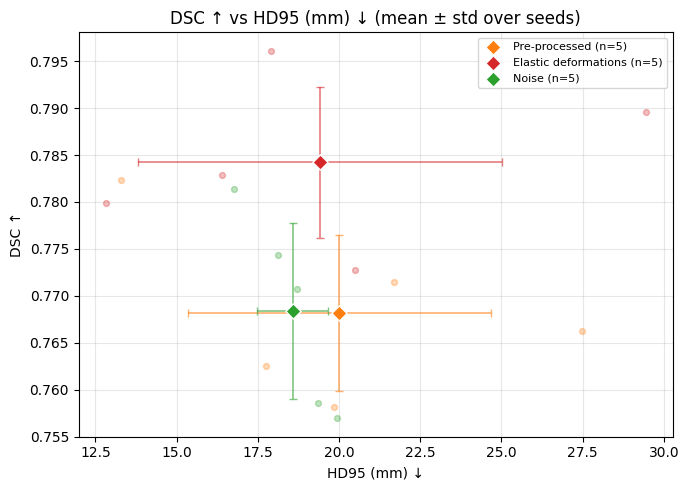

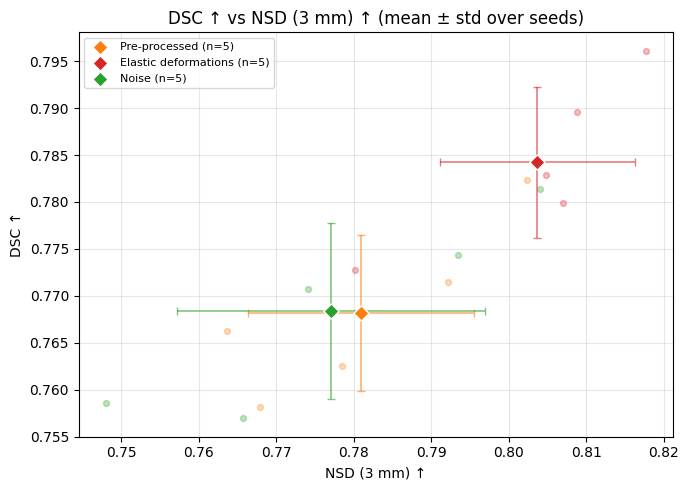

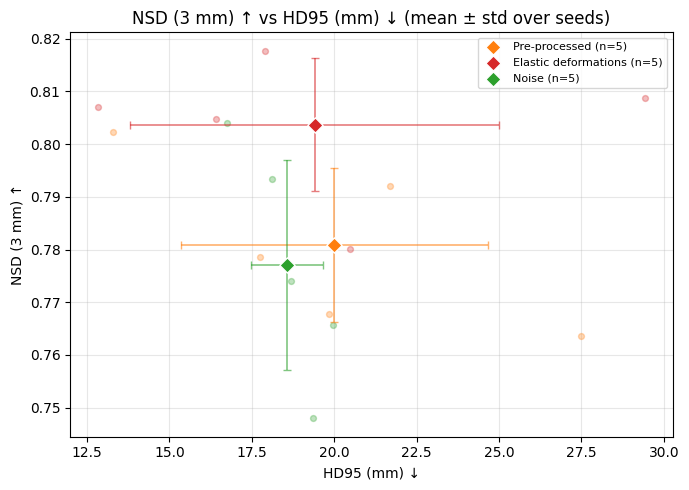

In [53]:
preprocessing_settings = ['segthor_preprocessed', 'segthor_Vnet_deformations', 'segthor_noise']
plot_comparisons([s for s in preprocessing_settings if s in results])


# Plots Comparing Optimizers

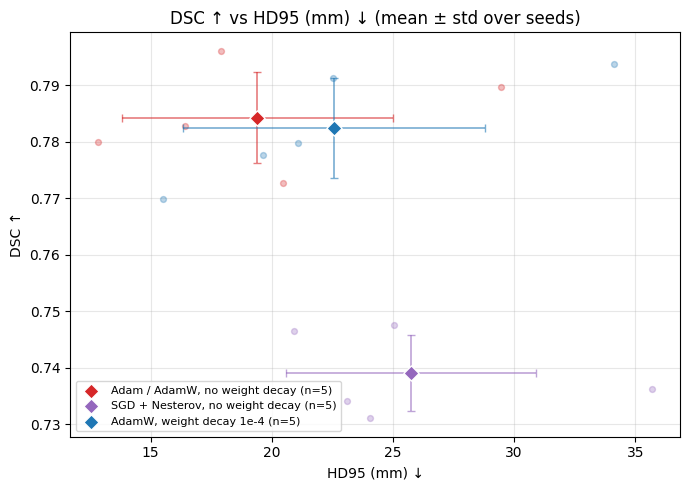

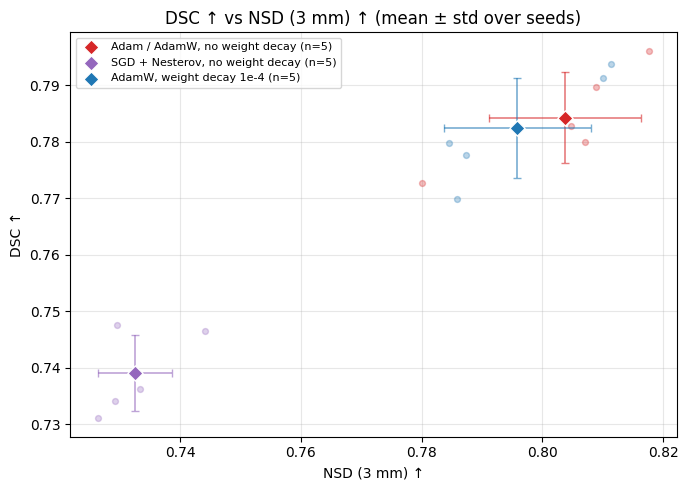

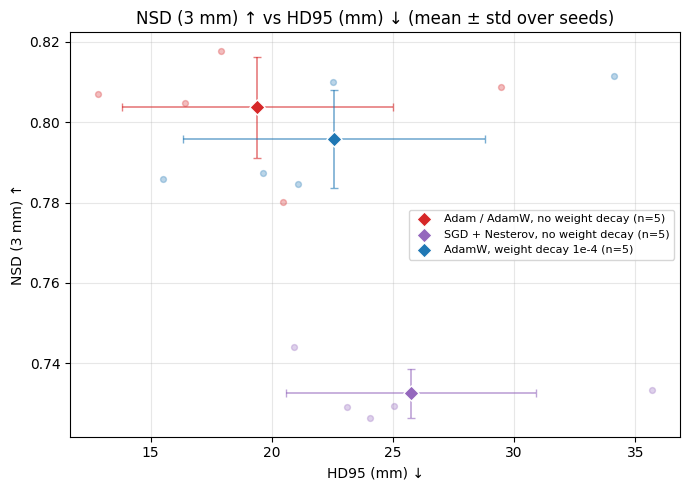

In [54]:
# All settings use 2D ENet at 256x256 with batch size 8. Elastic deformations is the Adam baseline without weight decay

optimizer_settings = ['segthor_Vnet_deformations', 'segthor_SGD', 'segthor_AdamW_weight_decay']
plot_comparisons([s for s in optimizer_settings if s in results],
                 legend_names={'segthor_Vnet_deformations': 'Adam / AdamW, no weight decay',
                               'segthor_SGD': 'SGD + Nesterov, no weight decay'}, 
                               colors={'segthor_Vnet_deformations': 'tab:red', 
                                       'segthor_SGD': 'tab:purple', 
                                       'segthor_AdamW_weight_decay': 'tab:blue'})


# Plots Comparing Resolution and Batch Size



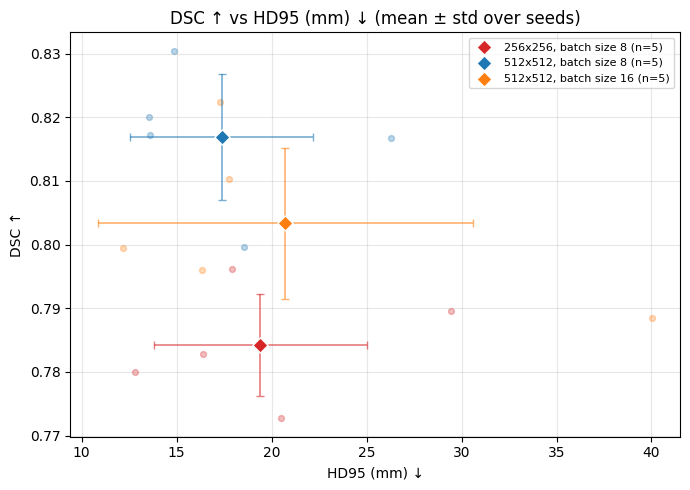

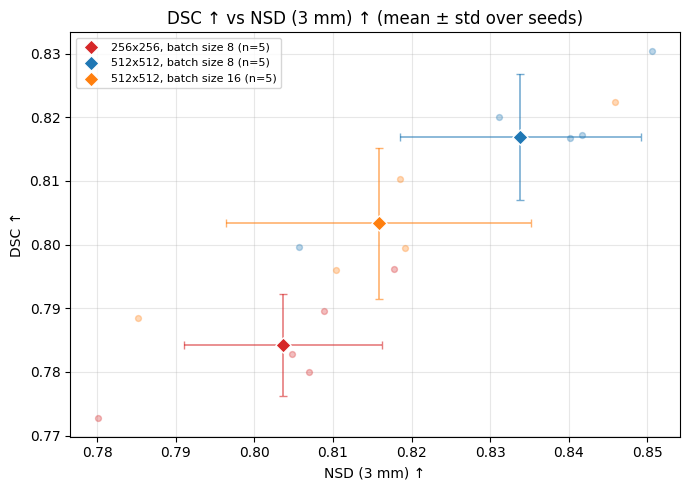

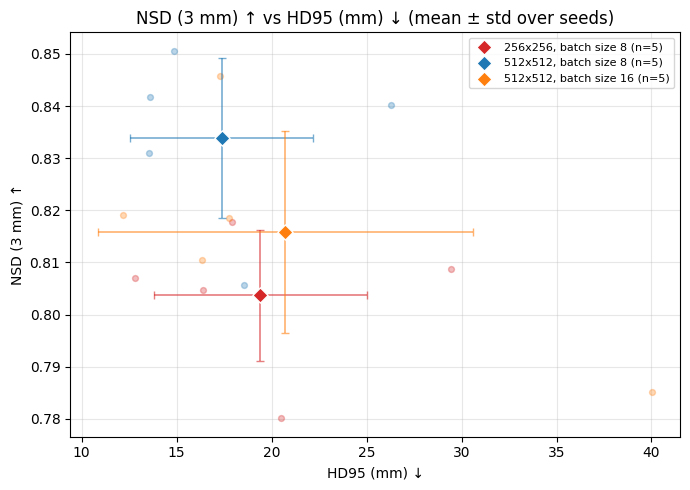

In [55]:
# All settings use 2D ENet with Adam and elastic deformations. Elastic deformations is the 256x256, batch size 8 baseline
resolution_settings = ['segthor_Vnet_deformations', 'segthor_512_Vnet', 'segthor_512_bs16']
plot_comparisons([s for s in resolution_settings if s in results], 
                 legend_names={'segthor_Vnet_deformations': '256x256, batch size 8',
                           'segthor_512_Vnet': '512x512, batch size 8',
                           'segthor_512_bs16': '512x512, batch size 16'})


# Plots Comparing Losses

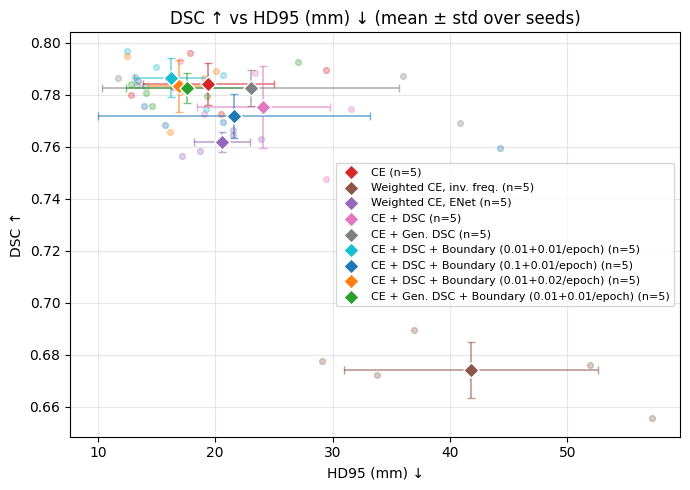

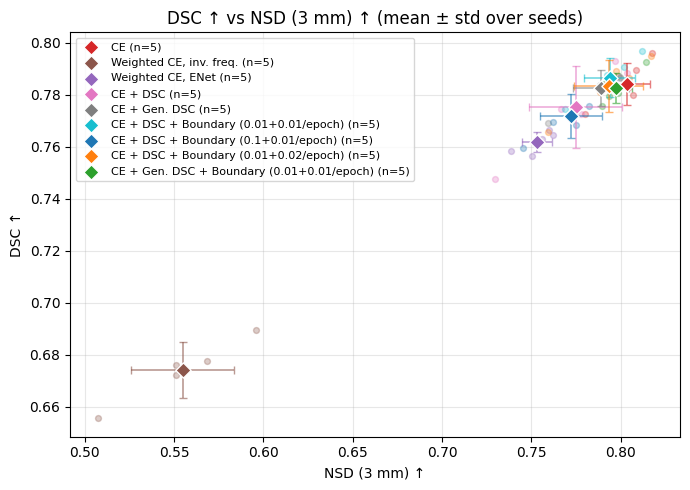

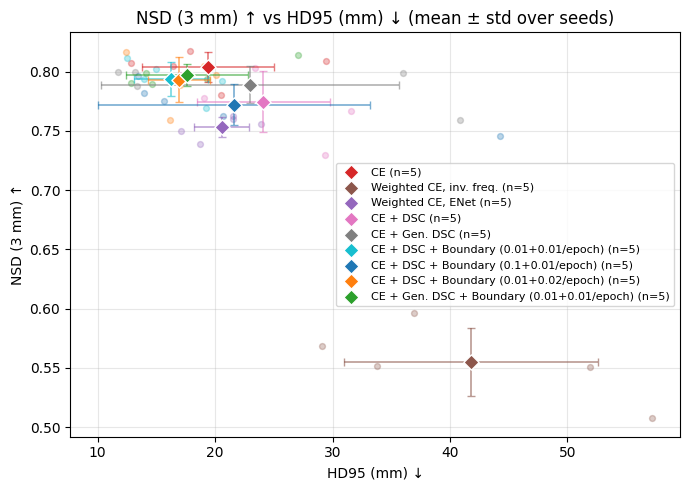

In [56]:
loss_settings = ['segthor_Vnet_deformations',
                 'segthor_weighted_ce_inv',
                 'segthor_weighted_ce_enet2',
                 'segthor_ce_dice_loss',
                 'segthor_ce_dice_loss_gen',
                 'segthor_three_losses_v1_correct',
                 'segthor_three_losses_v2',
                 'segthor_three_losses_v3',
                 'segthor_three_losses_v4',]

plot_comparisons([s for s in loss_settings if s in results],
                 legend_names={'segthor_Vnet_deformations': 'CE',
                                'segthor_weighted_ce_inv': 'Weighted CE, inv. freq.',
                                'segthor_weighted_ce_enet2': 'Weighted CE, ENet',
                                'segthor_ce_dice_loss': 'CE + DSC',
                                'segthor_ce_dice_loss_gen': 'CE + Gen. DSC',
                                'segthor_three_losses_v1_correct': 'CE + DSC + Boundary (0.01+0.01/epoch)',
                                'segthor_three_losses_v2': 'CE + DSC + Boundary (0.1+0.01/epoch)',
                                'segthor_three_losses_v3': 'CE + DSC + Boundary (0.01+0.02/epoch)',
                                'segthor_three_losses_v4': 'CE + Gen. DSC + Boundary (0.01+0.01/epoch)',},
                 colors={
                 'segthor_Vnet_deformations': 'tab:red',
                 'segthor_three_losses_v1_correct': 'tab:cyan',
                 'segthor_three_losses_v2': 'tab:blue',
                 'segthor_three_losses_v3': 'tab:orange',
                 'segthor_three_losses_v4': 'tab:green',
                 'segthor_weighted_ce_inv': 'tab:brown',
                 'segthor_weighted_ce_enet2': 'tab:purple',
                 'segthor_ce_dice_loss': 'tab:pink',
                 'segthor_ce_dice_loss_gen': 'tab:grey'
                 })


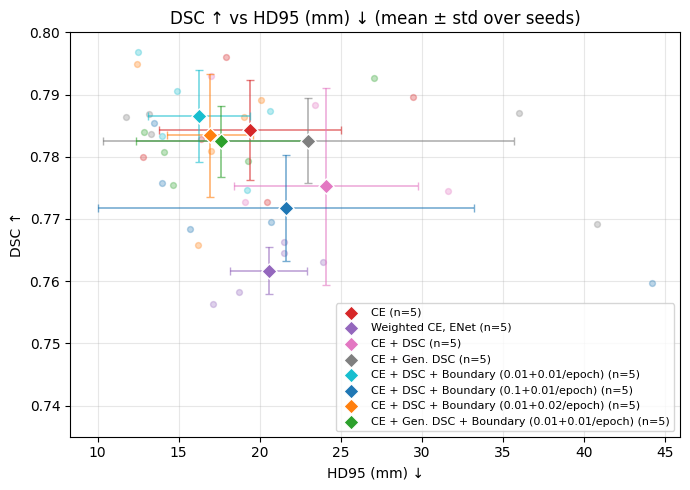

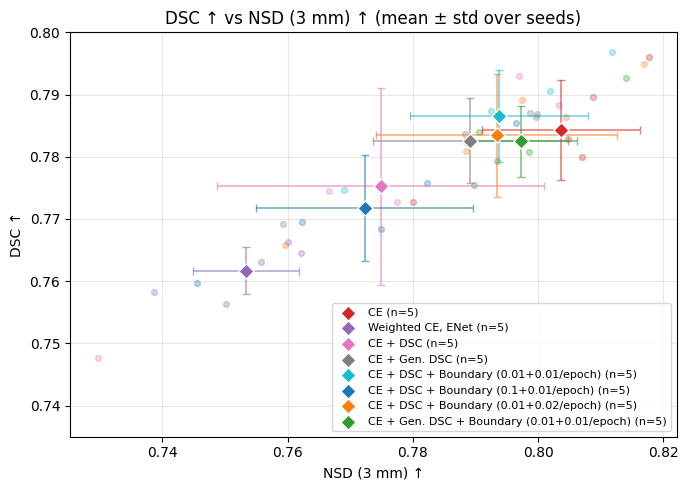

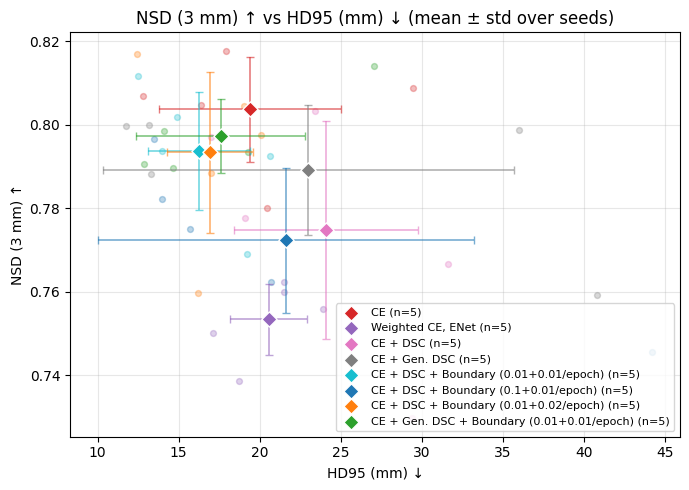

In [57]:
loss_settings = ['segthor_Vnet_deformations',
                 'segthor_weighted_ce_enet2',
                 'segthor_ce_dice_loss',
                 'segthor_ce_dice_loss_gen',
                 'segthor_three_losses_v1_correct',
                 'segthor_three_losses_v2',
                 'segthor_three_losses_v3',
                 'segthor_three_losses_v4',]

plot_comparisons([s for s in loss_settings if s in results],
                 legend_names={'segthor_Vnet_deformations': 'CE',
                                'segthor_weighted_ce_enet2': 'Weighted CE, ENet',
                                'segthor_ce_dice_loss': 'CE + DSC',
                                'segthor_ce_dice_loss_gen': 'CE + Gen. DSC',
                                'segthor_three_losses_v1_correct': 'CE + DSC + Boundary (0.01+0.01/epoch)',
                                'segthor_three_losses_v2': 'CE + DSC + Boundary (0.1+0.01/epoch)',
                                'segthor_three_losses_v3': 'CE + DSC + Boundary (0.01+0.02/epoch)',
                                'segthor_three_losses_v4': 'CE + Gen. DSC + Boundary (0.01+0.01/epoch)',},
                colors={
                    'segthor_Vnet_deformations': 'tab:red',
                    'segthor_three_losses_v1_correct': 'tab:cyan',
                    'segthor_three_losses_v2': 'tab:blue',
                    'segthor_three_losses_v3': 'tab:orange',
                    'segthor_three_losses_v4': 'tab:green',
                    'segthor_weighted_ce_enet2': 'tab:purple',
                    'segthor_ce_dice_loss': 'tab:pink',
                    'segthor_ce_dice_loss_gen': 'tab:grey'}, 
                axis_limits={
                    'dice': (0.735, 0.8)
                }
                )

# Plots Comparing Architecture


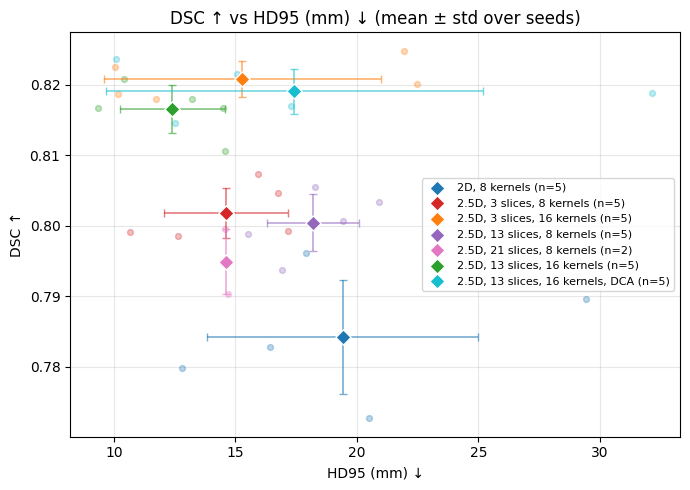

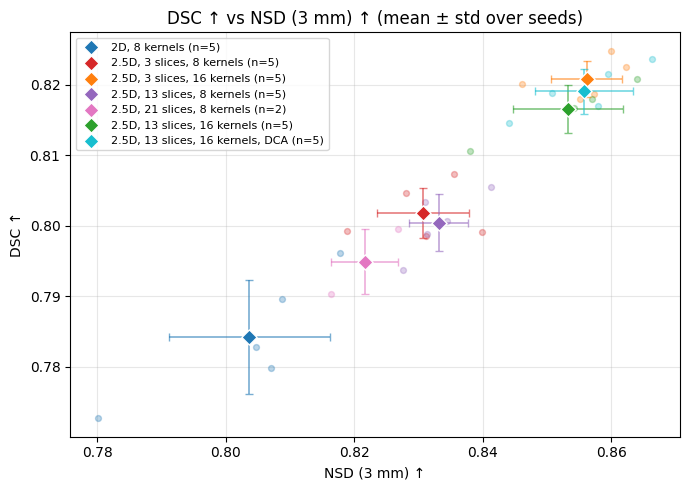

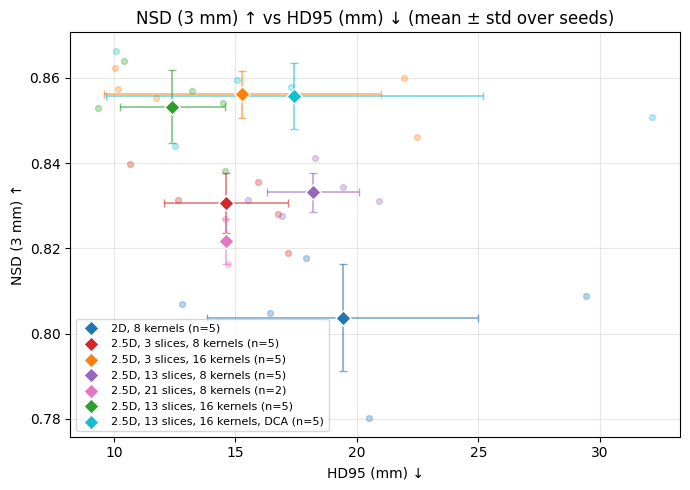

In [58]:
architecture_settings = ['segthor_Vnet_deformations',
                         'segthor_ENet25D_Competitive_Improved_3slices', 
                         'segthor_ENet25D_Competitive_Improved_16kernels_3slices', 
                         'segthor_ENet25D_Competitive_Improved_13slices', 
                         'segthor_ENet25D_Competitive_Improved_21slices', 
                         'segthor_ENet25D_Competitive_Improved_16kernels_13slices', 
                         'segthor_ENet25D_Competitive_Improved_dca_16kernels_13slices'
                         ]

plot_comparisons([s for s in architecture_settings if s in results],
                  legend_names = {'segthor_Vnet_deformations': '2D, 8 kernels', 
                           'segthor_ENet25D_Competitive_Improved_3slices': '2.5D, 3 slices, 8 kernels', 
                           'segthor_ENet25D_Competitive_Improved_16kernels_3slices': '2.5D, 3 slices, 16 kernels',
                           'segthor_ENet25D_Competitive_Improved_13slices': '2.5D, 13 slices, 8 kernels',
                           'segthor_ENet25D_Competitive_Improved_21slices': '2.5D, 21 slices, 8 kernels',
                           'segthor_ENet25D_Competitive_Improved_16kernels_13slices': '2.5D, 13 slices, 16 kernels', 
                           'segthor_ENet25D_Competitive_Improved_dca_16kernels_13slices': '2.5D, 13 slices, 16 kernels, DCA'},
                            colors={'segthor_Vnet_deformations': 'tab:blue', 
                                    'segthor_ENet25D_Competitive_Improved_3slices': 'tab:red', 
                                    'segthor_ENet25D_Competitive_Improved_16kernels_3slices': 'tab:orange',
                                    'segthor_ENet25D_Competitive_Improved_13slices': 'tab:purple',
                                    'segthor_ENet25D_Competitive_Improved_21slices': 'tab:pink',
                                    'segthor_ENet25D_Competitive_Improved_16kernels_13slices': 'tab:green', 
                                    'segthor_ENet25D_Competitive_Improved_dca_16kernels_13slices': 'tab:cyan'}
                            )


# Plots Comparing Post-processing on 512 resolution

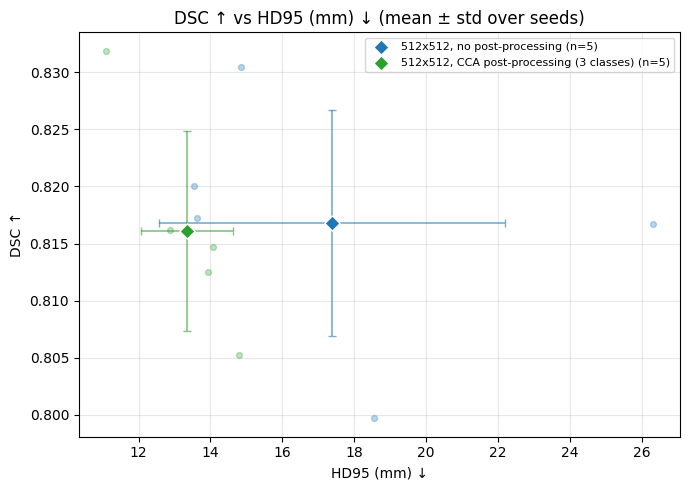

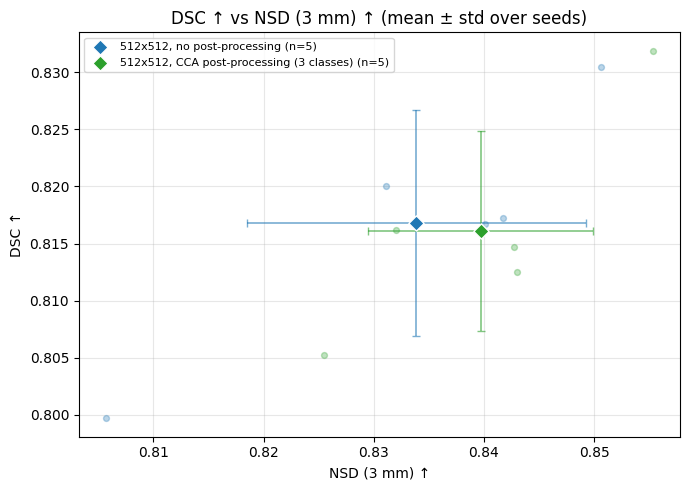

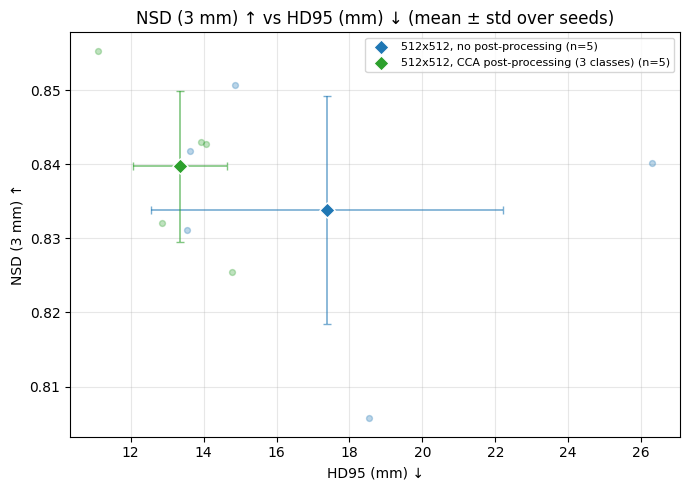

In [59]:
final_settings = ['segthor_512_Vnet','segthor_post_processing_18_3classes']
plot_comparisons([s for s in final_settings if s in results], 
                 legend_names={'segthor_512_Vnet': '512x512, no post-processing', 
                               'segthor_post_processing_18_3classes': '512x512, CCA post-processing (3 classes)'})


# Plots Comparing Everything

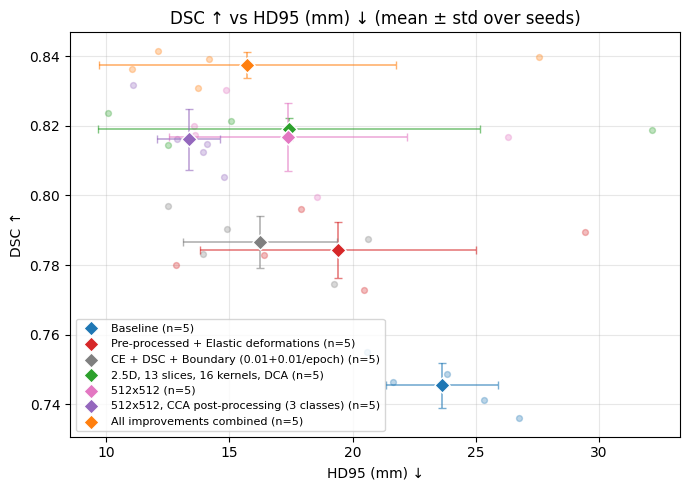

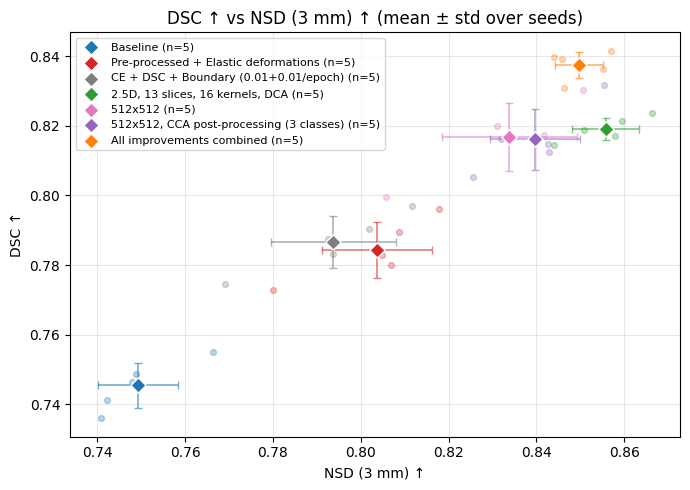

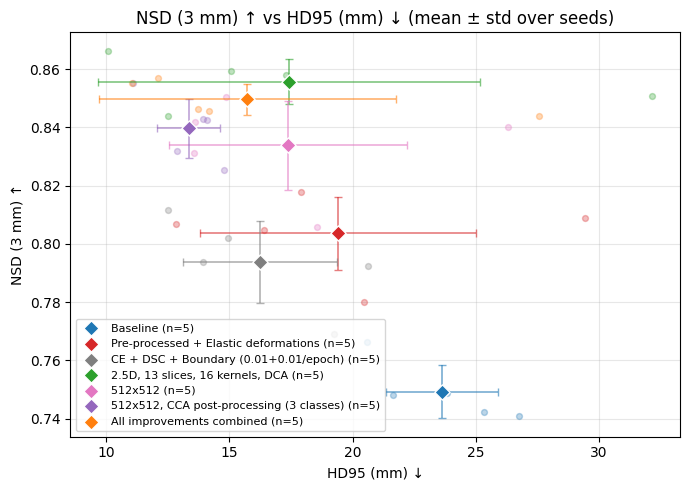

In [60]:
settings = ['segthor_baseline',  
            'segthor_Vnet_deformations',  
            'segthor_three_losses_v1_correct',
            'segthor_ENet25D_Competitive_Improved_dca_16kernels_13slices',
            'segthor_512_Vnet', 
            'segthor_post_processing_18_3classes',
            'segthor_ENet25D_Competitive_dca_16kernels_13slices_combined_loss_512',  
           ]

plot_comparisons([s for s in settings],
                 legend_names={'segthor_baseline': 'Baseline', 
                               'segthor_Vnet_deformations': 'Pre-processed + Elastic deformations',
                               'segthor_three_losses_v1_correct': 'CE + DSC + Boundary (0.01+0.01/epoch)', 
                               'segthor_ENet25D_Competitive_Improved_dca_16kernels_13slices': '2.5D, 13 slices, 16 kernels, DCA',
                               'segthor_512_Vnet': '512x512', 
                               'segthor_post_processing_18_3classes': '512x512, CCA post-processing (3 classes)', 
                               'segthor_ENet25D_Competitive_dca_16kernels_13slices_combined_loss_512': 'All improvements combined',
                               }, 
                 colors={'segthor_baseline': 'tab:blue',
                         'segthor_Vnet_deformations': 'tab:red',
                         'segthor_three_losses_v1_correct': 'tab:gray',
                         'segthor_ENet25D_Competitive_Improved_dca_16kernels_13slices': 'tab:green',
                         'segthor_512_Vnet': 'tab:pink',
                         'segthor_post_processing_18_3classes': 'tab:purple',
                         'segthor_ENet25D_Competitive_dca_16kernels_13slices_combined_loss_512': 'tab:orange',
                          })

# Plot Comparing Classes for the Best Setting


Best mean overall Dice: 0.8376.


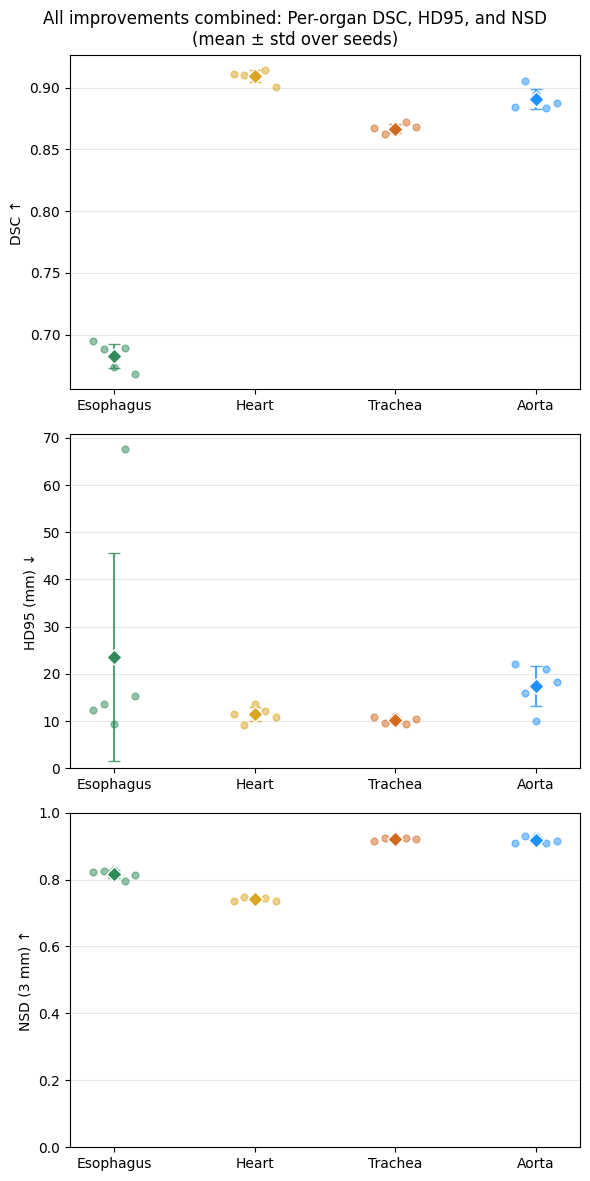

In [61]:
import matplotlib.pyplot as plt

def plot_best_classes():
    # Select the best setting by mean overall Dice across available seeds
    data = results

    best_setting = select_best_setting()
    best_score = statistics(data[best_setting]["overall_dice"])[0]

    colors = ["seagreen", "goldenrod", "chocolate", "dodgerblue"]
    organs = list(ORGANS.values())
    offsets = np.linspace(-0.15, 0.15, len(SEEDS)) # fixed jitter so every seed is visible

    fig, axes = plt.subplots(3, 1, figsize=(6, 12))
    for ax, metric, ylabel in zip(axes, ["dice", "hd", "nsd"],
                                  [metric_labels[m] for m in ("dice", "hd", "nsd")]):
        for j, organ in enumerate(organs):
            v = data[best_setting][metric][:, j]
            ok = np.isfinite(v)
            if not ok.any():
                continue
            m, s, _ = statistics(v[ok])
            c = colors[j]
            ax.scatter(j + offsets[ok], v[ok], color=c, alpha=0.5, s=24, zorder=2)   # seeds
            ax.scatter(j, m, marker="D", s=60, color=c, edgecolors="white", linewidths=1,
                                   zorder=4, label=f"{organ} (n={ok.sum()})")
            ax.errorbar(j, m, yerr=s, fmt="none", color=c, alpha=0.8, ms=7, capsize=4, zorder=3)   # mean ± std
            
        ax.set_xticks(range(len(organs)))
        ax.set_xticklabels(organs)
        ax.set_ylabel(ylabel)
        ax.grid(axis="y", alpha=0.3)
        ax.set_axisbelow(True)
    
    axes[1].set_ylim(bottom=0)
    axes[2].set_ylim(bottom=0, top=1.0)

    fig.suptitle(f"{label(best_setting)}: Per-organ DSC, HD95, and NSD\n"
                 f"(mean ± std over seeds)")
    print(f"Best mean overall Dice: {best_score:.4f}.")
    fig.tight_layout()
    plt.show()

plot_best_classes()


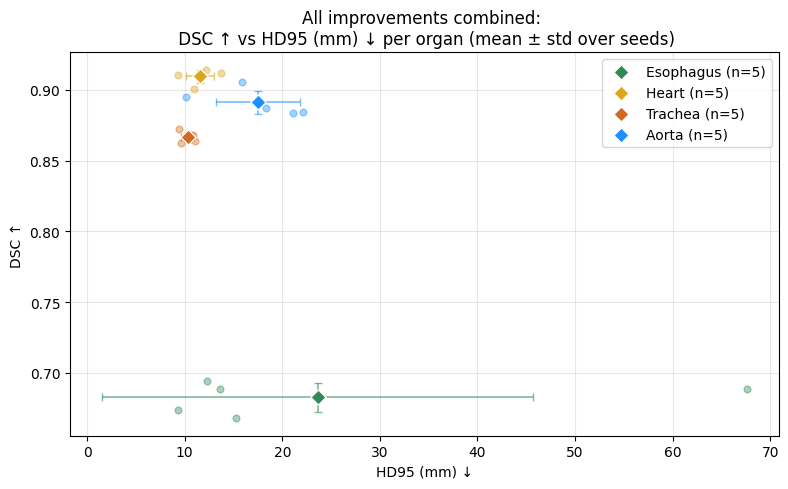

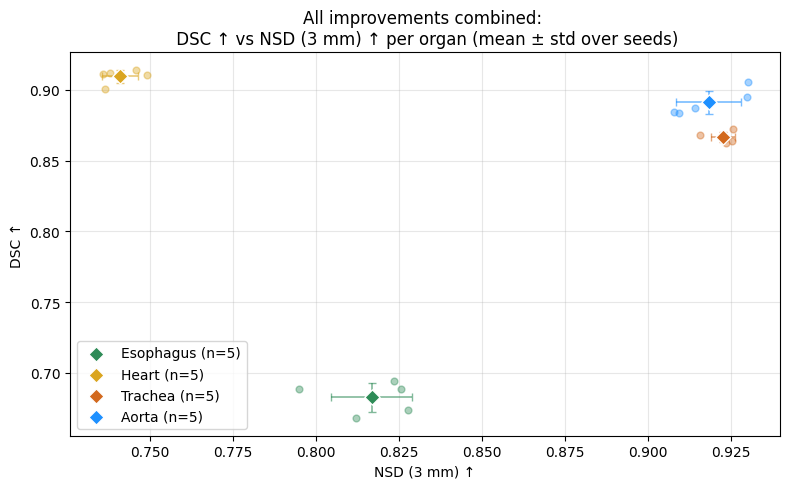

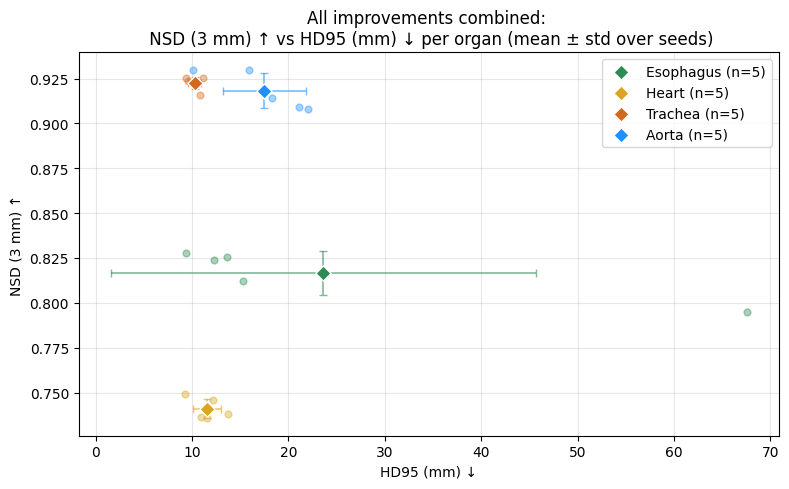

Best mean overall DSC: 0.8376.


In [62]:
import matplotlib.pyplot as plt

def plot_best_classes_scatter():
    # Select the best setting by mean overall Dice across available seeds
    data = results

    best_setting = select_best_setting()
    best_score = statistics(data[best_setting]["overall_dice"])[0]
    best = data[best_setting]
    
    colors = ["seagreen", "goldenrod", "chocolate", "dodgerblue"]
    for x_metric, y_metric in metric_pairs:
        fig, ax = plt.subplots(figsize=(8, 5))
        for j, organ in enumerate(ORGANS.values()):
            d, n = best[y_metric][:, j], best[x_metric][:, j]
            ok = np.isfinite(d) & np.isfinite(n)   # same seeds for both metrics
            if not ok.any():
                continue
            dm, ds, _ = statistics(d[ok])
            nm, ns, _ = statistics(n[ok])
            c = colors[j]
            ax.scatter(n[ok], d[ok], color=c, alpha=0.4, s=24, zorder=2)  # seeds
            ax.errorbar(nm, dm, xerr=ns, yerr=ds, fmt="none", ecolor=c, elinewidth=1.2,
                        capsize=3, alpha=0.6, zorder=3)   # std
            ax.scatter(nm, dm, marker="D", s=60, color=c, edgecolors="white", linewidths=1,
                       zorder=4, label=f"{organ} (n={ok.sum()})")   # mean

        ax.set_xlabel(metric_labels[x_metric])
        ax.set_ylabel(metric_labels[y_metric])
        ax.grid(alpha=0.3)
        ax.set_title(f"{label(best_setting)}: \n {metric_labels[y_metric]} vs {metric_labels[x_metric]} per organ (mean ± std over seeds)")
        ax.legend(fontsize=10)
        plt.tight_layout()
        plt.show()
        
    print(f"Best mean overall DSC: {best_score:.4f}.")

plot_best_classes_scatter()


## Performance Across Patients per Class for Best Setting


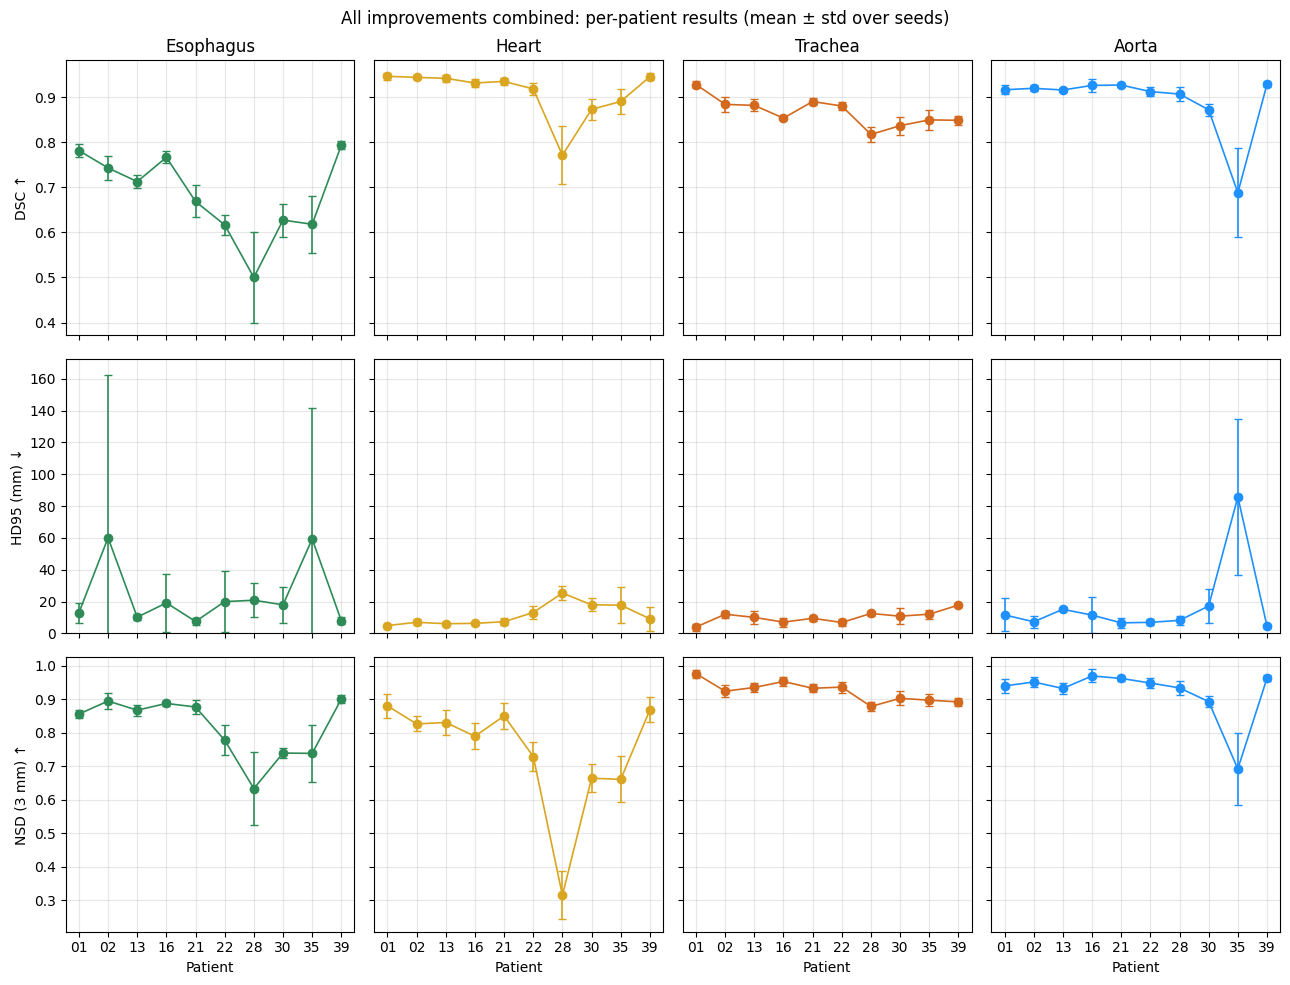

In [63]:
import matplotlib.pyplot as plt

def plot_patients(setting=None):
    if setting is None:
        setting = select_best_setting()
    dice_seeds, hd_seeds, nsd_seeds, reference = [], [], [], None
    for seed in SEEDS:
        folder = results_dir / setting / f"ce_seed{seed}" / "metrics_3d"
        if not all((folder / f"{metric}_3d_val.npy").is_file() for metric in ("dice", "hd", "nsd")):
            continue
        dice, hd, nsd, patients = load_offline_metrics(folder)
        assert len(set(patients)) == len(patients), "Duplicate patient IDs."
        order = np.argsort(patients)   # sorted by ID, matches patients across seeds
        patients = patients[order]
        dice = dice[order][:, 1:]   # drop background
        hd = hd[order][:, 1:]
        nsd = nsd[order][:, 1:]
        if reference is None:
            reference = patients
        assert np.array_equal(patients, reference), "All seeds must use the same validation patients."

        dice_seeds.append(dice)
        hd_seeds.append(hd)
        nsd_seeds.append(nsd)

    # Mean and std over seeds for every patient and organ
    scores = {}
    for metric, values in [("dice", np.array(dice_seeds)), ("hd", np.array(hd_seeds)), ("nsd", np.array(nsd_seeds))]:
        mean = np.full(values.shape[1:], np.nan)  # values: (seeds, patients, organs)
        std = np.full_like(mean, np.nan)
        for p, o in np.ndindex(mean.shape):
            mean[p, o], std[p, o], _ = statistics(values[:, p, o])
        scores[metric] = {"mean": mean, "std": std}
        bad = (~np.isfinite(values)).sum()
        if bad:
            print(f"{metric}: {bad} of {values.size} values nonfinite, excluded.")

    x = np.arange(len(reference))
    names = [str(p).replace("Patient_", "") for p in reference]
    colors = ["seagreen", "goldenrod", "chocolate", "dodgerblue"]
    organs = list(ORGANS.values())

    fig, axes = plt.subplots(3, len(organs), figsize=(13, 10), sharex=True, sharey="row")
    for r, (metric, ylabel) in enumerate([(m, metric_labels[m]) for m in ("dice", "hd", "nsd")]):
        for j, organ in enumerate(organs):
            ax = axes[r, j]
            ax.errorbar(x, scores[metric]["mean"][:, j], yerr=scores[metric]["std"][:, j],
                        fmt="o-", color=colors[j], ms=6, lw=1.2, elinewidth=1.2, capsize=3)
            ax.grid(alpha=0.3)
            if r == 0:
                ax.set_title(organ)
            if j == 0:
                ax.set_ylabel(ylabel)
            if r == 2:
                ax.set_xlabel("Patient")
    
    axes[1, 0].set_ylim(bottom=0)  # HD >= 0; whiskers below are clipped
    axes[1, 0].set_xticks(x)
    axes[1, 0].set_xticklabels(names)

    fig.suptitle(f"{label(setting)}: per-patient results (mean ± std over seeds)")
    fig.tight_layout()
    plt.show()

    scores["patients"] = reference
    return scores

patient_comparison = plot_patients()

## Baseline vs Best Setting: All Metric Pairs per Organ


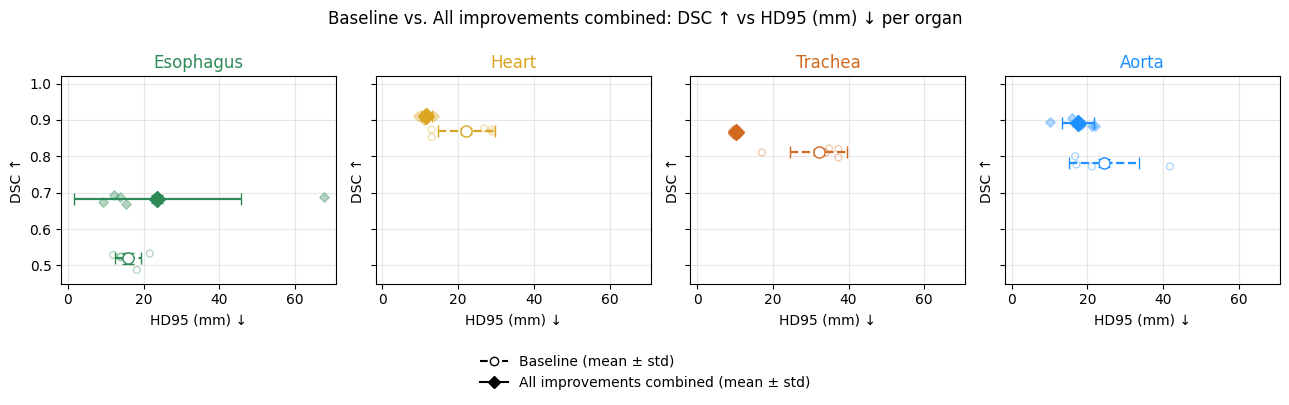

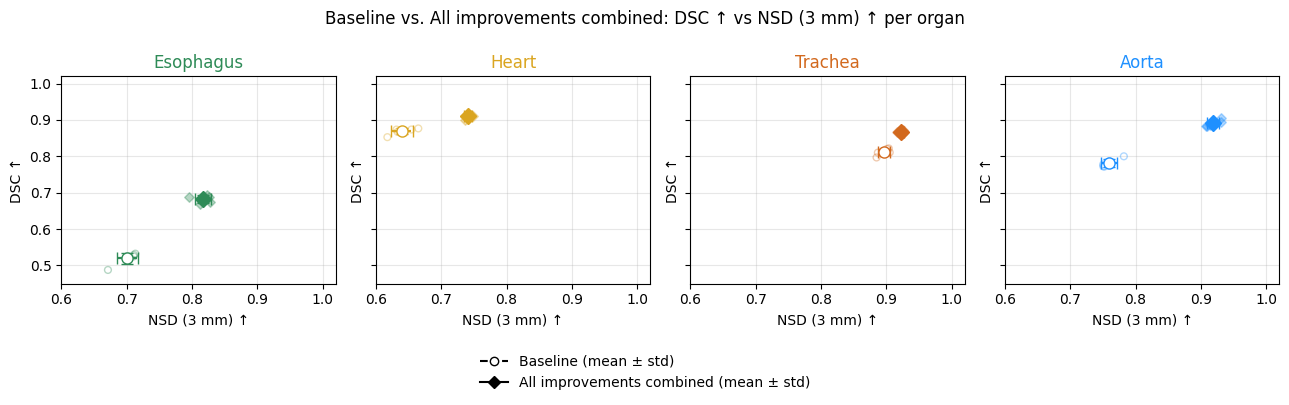

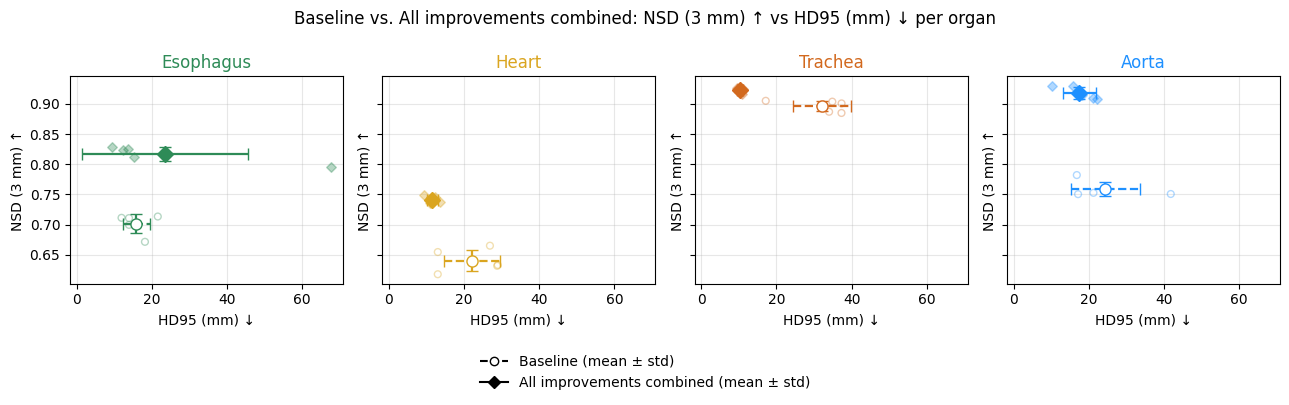

Best setting selected by mean overall DSC: All improvements combined


In [64]:
from matplotlib.lines import Line2D

def plot_baseline_vs_best_organs():
    
    baseline_setting = "segthor_baseline"
    best_setting = select_best_setting()
    colors = ["seagreen", "goldenrod", "chocolate", "dodgerblue"]
    for x_metric, y_metric in metric_pairs:
        fig, axes = plt.subplots(1, 4, figsize=(13, 4), sharex=True, sharey=True)
        comparisons = [(baseline_setting, "o", "--", False),
                       (best_setting, "D", "-", True)]

        for j, (ax, organ, color) in enumerate(zip(axes.flat, ORGANS.values(), colors)):
            for setting, marker, linestyle, filled in comparisons:
                d = results[setting][y_metric][:, j]
                n = results[setting][x_metric][:, j]
                valid = np.isfinite(d) & np.isfinite(n)
                if not valid.any():
                    continue
                dm, ds, _ = statistics(d[valid])
                nm, ns, _ = statistics(n[valid])
                ax.scatter(n[valid], d[valid], marker=marker, s=24,
                           facecolors=color if filled else "none", edgecolors=color,
                           alpha=0.35, zorder=2)
                bars = ax.errorbar(nm, dm, xerr=ns, yerr=ds, fmt=marker,
                                   color=color, markerfacecolor=color if filled else "white",
                                   markeredgecolor=color, markersize=8, capsize=4,
                                   elinewidth=1.6, zorder=3)
                # Error-bar segments need their own style
                for collection in bars.lines[2]:
                    collection.set_linestyle(linestyle)
            ax.set_title(organ, color=color)
            ax.set_xlabel(metric_labels[x_metric])
            ax.set_ylabel(metric_labels[y_metric])
            ax.grid(alpha=0.3)
            ax.set_axisbelow(True)
            if x_metric == "nsd":
                ax.set_xlim(0.6, 1.02)
            if y_metric == "dice":
                ax.set_ylim(0.45, 1.02)

        handles = [Line2D([], [], color="black", marker="o", markerfacecolor="white",
                          linestyle="--", label="Baseline (mean ± std)"),
                   Line2D([], [], color="black", marker="D", linestyle="-",
                          label=f"{label(best_setting)} (mean ± std)")]
        fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 0),
                   frameon=False)
        fig.suptitle(f"Baseline vs. {label(best_setting)}: {metric_labels[y_metric]} vs {metric_labels[x_metric]} per organ")
        fig.tight_layout(rect=(0, 0.15, 1, 0.99))
        plt.show()
    print(f"Best setting selected by mean overall DSC: {label(best_setting)}")

plot_baseline_vs_best_organs()


## Export Submission Metrics — Seed 2


In [65]:
from pathlib import Path
import numpy as np
import warnings

# Get offline results directory
project = Path.cwd()
if not (project / "offline_results").is_dir():
    project = project.parent
results_dir = project / "offline_results"
assert results_dir.is_dir(), f"Not found: {results_dir}"

export_setting = "segthor_ENet25D_Competitive_dca_16kernels_13slices_combined_loss_512"
export_seed = 2

metric_folder = results_dir / export_setting / f"ce_seed{export_seed}" / "metrics_3d"

export_dir = results_dir / export_setting / f"ce_seed{export_seed}" / "submission_metrics"
export_dir.mkdir(parents=True, exist_ok=True)

patients = np.load(metric_folder / "patients_val.npy")
print(f"patients_val.npy: shape {patients.shape}")
assert patients.ndim == 1 and len(patients) > 0, "Expected a nonempty 1D patient-ID array"
assert len(set(patients.tolist())) == len(patients), "Duplicate patient IDs"

for metric, archive_name in [
    ("dice", "3d_dice.npz"),
    ("hd", "3d_hd95.npz"),
    ("nsd", "3d_nsd3mm.npz")
]:
    values = np.load(metric_folder / f"{metric}_3d_val.npy")

    # Print original shape
    print(f"\n{metric}_3d_val.npy: shape {values.shape}")
    # Check for NaN values in original file
    nan_count = np.isnan(values).sum()
    if nan_count > 0:
        warnings.warn(f"{metric}_3d_val.npy contains {nan_count} NaN values!")

    assert values.ndim == 2 and values.shape == (len(patients), 5)

    # Each patient maps to a K=5 vector: background, esophagus, heart, trachea, aorta
    # Preserve saved background values (NaN if background was not evaluated)
    patient_scores = {
        str(patient): values[row]
        for row, patient in enumerate(patients)
    }
    archive_path = export_dir / archive_name
    np.savez_compressed(archive_path, **patient_scores)

    # Check if it was saved correctly
    with np.load(archive_path) as archive:
        assert set(archive.files) == set(patient_scores)
        for patient, scores in patient_scores.items():
            assert archive[patient].shape == (5,), f"Unexpected shape for {patient}: {archive[patient].shape}"
            np.testing.assert_equal(archive[patient], scores)
        
        for patient in archive.files:
            print(patient, archive[patient].shape)

        # Check final archive shape and NaN values
        final_values = np.stack([archive[patient] for patient in patient_scores])
        assert final_values.shape == values.shape, "Exported matrix shape differs from input"
        print(f"{archive_name}: shape {final_values.shape}")
        final_nan_count = np.isnan(final_values).sum()
        if final_nan_count > 0:
            warnings.warn(f"{archive_name} contains {final_nan_count} NaN values!")

    print(f"Saved to: {archive_path}")

print(f"\nNSD tolerance: {float(np.load(metric_folder / 'nsd_tolerance_mm.npy')):g} mm")

patients_val.npy: shape (10,)

dice_3d_val.npy: shape (10, 5)
Patient_01 (5,)
Patient_02 (5,)
Patient_13 (5,)
Patient_16 (5,)
Patient_21 (5,)
Patient_22 (5,)
Patient_28 (5,)
Patient_30 (5,)
Patient_35 (5,)
Patient_39 (5,)
3d_dice.npz: shape (10, 5)
Saved to: /gpfs/home3/scur0178/ai4mi_project_group7/offline_results/segthor_ENet25D_Competitive_dca_16kernels_13slices_combined_loss_512/ce_seed2/submission_metrics/3d_dice.npz

hd_3d_val.npy: shape (10, 5)
Patient_01 (5,)
Patient_02 (5,)
Patient_13 (5,)
Patient_16 (5,)
Patient_21 (5,)
Patient_22 (5,)
Patient_28 (5,)
Patient_30 (5,)
Patient_35 (5,)
Patient_39 (5,)
3d_hd95.npz: shape (10, 5)
Saved to: /gpfs/home3/scur0178/ai4mi_project_group7/offline_results/segthor_ENet25D_Competitive_dca_16kernels_13slices_combined_loss_512/ce_seed2/submission_metrics/3d_hd95.npz

nsd_3d_val.npy: shape (10, 5)
Patient_01 (5,)
Patient_02 (5,)
Patient_13 (5,)
Patient_16 (5,)
Patient_21 (5,)
Patient_22 (5,)
Patient_28 (5,)
Patient_30 (5,)
Patient_35 (5,)
Patie

# Best Setting— Seed 2 Metric Table


In [66]:
from pathlib import Path
import numpy as np
from IPython.display import HTML, display

seed2_setting = "segthor_ENet25D_Competitive_dca_16kernels_13slices_combined_loss_512"
seed2_folder = results_dir / seed2_setting / "ce_seed2" / "metrics_3d"
seed2_patients = np.load(seed2_folder / "patients_val.npy")
seed2_tolerance = float(np.load(seed2_folder / "nsd_tolerance_mm.npy"))
seed2_rows = list(ORGANS.values()) + ["Across organ means"]
seed2_table = {}

for metric, title in [("dice", "DSC"), ("hd", "HD95 (mm)"), ("nsd", f"NSD ({seed2_tolerance:g} mm)")]:
    values = np.load(seed2_folder / f"{metric}_3d_val.npy")
    assert values.shape == (len(seed2_patients), 5)
    organ_stats = [statistics(values[:, class_id]) for class_id in ORGANS]
    organ_means = np.array([mean for mean, std, count in organ_stats])
    overall_mean, overall_std, _ = statistics(organ_means)
    seed2_table[title] = [f"{mean:.4f} ± {std:.4f}" for mean, std, count in organ_stats]
    seed2_table[title].append(f"{overall_mean:.4f} ± {overall_std:.4f}")

print(f"All improvements combined — seed 2, {len(seed2_patients)} patients")
header = "<tr><th>Organ / summary</th>" + "".join(f"<th>{column}</th>" for column in seed2_table) + "</tr>"
rows = ["<tr><th>" + organ + "</th>" + "".join(f"<td>{values[i]}</td>" for values in seed2_table.values()) + "</tr>"
        for i, organ in enumerate(seed2_rows)]
display(HTML("<table>" + header + "".join(rows) + "</table>"))


All improvements combined — seed 2, 10 patients


Organ / summary,DSC,HD95 (mm),NSD (3 mm)
Esophagus,0.6739 ± 0.0900,9.3307 ± 2.7380,0.8278 ± 0.0761
Heart,0.9118 ± 0.0385,13.6923 ± 10.2320,0.7380 ± 0.1390
Trachea,0.8641 ± 0.0294,11.0996 ± 4.2456,0.9254 ± 0.0270
Aorta,0.8952 ± 0.0802,10.1374 ± 12.6710,0.9299 ± 0.0853
Across organ means,0.8363 ± 0.0953,11.0650 ± 1.6411,0.8553 ± 0.0790
